# `Anisotropy` Tutorial

This tutorial introduces the `anisotropy` module of `hasasia`: per-direction effective sensitivity curves and detection statistics for pulsar timing arrays. For isotropic-sky sensitivity-curve basics, see the main `hasasia` tutorial.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import healpy as hp
import astropy.units as u
import astropy.constants as c

import itertools

import hasasia
import hasasia.sensitivity as hsen
import hasasia.sim as hsim
import hasasia.skymap as hsky
import hasasia.anisotropy as haniso
import hasasia.forecast as hfor

import pickle
import os
import gc

import matplotlib as mpl
import warnings
warnings.filterwarnings('ignore', message='"verbose" was deprecated')
warnings.filterwarnings('ignore', message='This figure includes Axes that are not compatible')

plt.rcParams['figure.dpi'] = 300
plt.rcParams['figure.figsize'] = [5,3]
plt.rcParams['text.usetex'] = True
plt.rcParams['figure.facecolor'] = 'white'

In [2]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib as mpl

# Custom purple colormap registered for healpy mollview
# (cmap='purple_cmap' / 'purple_cmap_r').
_purple_colors = ["#FFFFFF", "#F2E7F7", "#CBB4E9", "#9C7FCF",
                  "#6A49A8", "#4C2C89", "#2A155D", "#1A0B30"]
_purple_pos = [0.0, 0.125, 0.25, 0.375, 0.5, 0.625, 0.75, 1.0]
purple_cmap = LinearSegmentedColormap.from_list(
    "purple_cmap", list(zip(_purple_pos, _purple_colors)), N=1024)
purple_cmap_r = purple_cmap.reversed()
for name, cm in [('purple_cmap', purple_cmap), ('purple_cmap_r', purple_cmap_r)]:
    if name not in mpl.colormaps:
        mpl.colormaps.register(cm, name=name)

pulsar_color = "#FE5C00"


## Simulated PTAs

We use two simulated PTA configurations built with `hsim.sim_pta(...)`. Both have 500 ns white-noise RMS and pulsar positions sampled from a von Mises-Fisher distribution centred near the Galactic plane (mild concentration), mimicking real-PTA clustering rather than a uniform sky.

- **`ASM_15`**: 100 pulsars, 15-year baseline — the small-array demo used throughout most of this tutorial.
- **`ASM_30`**: 150 pulsars, 30-year baseline — the same 100 pulsars from `ASM_15` (now with 30-year baselines) plus 50 new ones, modelling a realistic forecast where existing pulsars gain longer baselines and new pulsars are added.

The "Alternative: load your own PTA data" section below shows the call pattern for real-data users.

*Note on noise:* 500 ns white-noise RMS sits at the optimistic end of realistic per-pulsar noise (typical PTA pulsars span ~0.1-5 us), and the simulated arrays use homogeneous noise with no red-noise injection. Real forecasts use heterogeneous per-pulsar noise budgets - we keep things simple here to demonstrate the framework, not to produce a realistic detection forecast.

In [3]:
# Helper: vMF-clustered pulsar positions (mimicking real-PTA clustering)
def _vmf_sky(N, mu_theta, mu_phi, kappa, seed):
    """Sample N (phi, theta) from a von Mises-Fisher distribution on the sphere
    centred on (mu_theta, mu_phi) with concentration `kappa`. kappa=0 -> uniform."""
    rng = np.random.default_rng(seed)
    out = []
    while len(out) < N:
        n_try = max(N * 3, N - len(out))
        phi_c = rng.uniform(0, 2*np.pi, size=n_try)
        theta_c = np.arccos(rng.uniform(-1, 1, size=n_try))
        cos_d = (np.sin(theta_c)*np.sin(mu_theta)*np.cos(phi_c - mu_phi)
                 + np.cos(theta_c)*np.cos(mu_theta))
        accept = rng.uniform(0, 1, size=n_try) < np.exp(kappa*(cos_d - 1))
        out.extend(zip(phi_c[accept], theta_c[accept]))
    out = out[:N]
    return np.array([p[0] for p in out]), np.array([p[1] for p in out])

# Cluster centre near the Galactic plane in the southern sky; mild concentration
MU_THETA, MU_PHI, KAPPA = 2.0, 4.7, 2.0

# 15-year array: 100 pulsars
phi_15, theta_15 = _vmf_sky(N=100, mu_theta=MU_THETA, mu_phi=MU_PHI,
                            kappa=KAPPA, seed=15)
psrs_15 = hsim.sim_pta(timespan=15.0, cad=23, sigma=5e-7,
                       phi=phi_15, theta=theta_15)

# 30-year array: same 100 pulsars (now with 30-yr baselines) + 50 new ones
phi_new, theta_new = _vmf_sky(N=50, mu_theta=MU_THETA, mu_phi=MU_PHI,
                              kappa=KAPPA, seed=30)
phi_30   = np.concatenate([phi_15,   phi_new])
theta_30 = np.concatenate([theta_15, theta_new])
psrs_30 = hsim.sim_pta(timespan=30.0, cad=23, sigma=5e-7,
                       phi=phi_30, theta=theta_30)

print(f"psrs_15: {len(psrs_15)} pulsars / 15 yr")
print(f"psrs_30: {len(psrs_30)} pulsars / 30 yr (first 100 shared with psrs_15)")


psrs_15: 100 pulsars / 15 yr
psrs_30: 150 pulsars / 30 yr (first 100 shared with psrs_15)


In [4]:
freqs = np.logspace(np.log10(3e-10), np.log10(2e-7), 300)

specs_15 = [hsen.Spectrum(p, freqs=freqs) for p in psrs_15]
for sp in specs_15:
    sp.NcalInv

specs_30 = [hsen.Spectrum(p, freqs=freqs) for p in psrs_30]
for sp in specs_30:
    sp.NcalInv


### Alternative: load your own PTA data

For real PTA data (par/tim files plus optional noise files),
`hasasia` works with `enterprise.pulsar.Pulsar` objects.  See the
`real_data_tutorial.ipynb`
for the full pipeline (timing-model fitting, noise-parameter loading,
etc.).  The cell below is a minimum scaffold; uncomment and update the
paths to use it.


In [5]:
# from enterprise.pulsar import Pulsar as ePulsar
# import glob
#
# pardir = 'path/to/par_files/'
# timdir = 'path/to/tim_files/'
# pars = sorted(glob.glob(pardir + '*.par'))
# tims = sorted(glob.glob(timdir + '*.tim'))
#
# # Build enterprise Pulsar objects (one per par/tim pair)
# epsrs = [ePulsar(p, t, ephem='DE436') for p, t in zip(pars, tims)]
#
# # Wrap as hasasia.Pulsar (handles ecliptic conversion, design matrix, etc.)
# real_psrs = [hsen.Pulsar(toas=ep.toas, toaerrs=ep.toaerrs,
#                          phi=ep.phi, theta=ep.theta,
#                          designmatrix=ep.Mmat, N=ep.N,
#                          pdist=ep.pdist) for ep in epsrs]
#
# real_freqs = np.logspace(np.log10(3e-10), np.log10(2e-7), 300)
# real_spectra = [hsen.Spectrum(p, freqs=real_freqs) for p in real_psrs]
# for sp in real_spectra:
#     sp.NcalInv
#
# # Once NcalInv is cached, the timing matrices can be freed to save memory:
# for sp in real_spectra:
#     del sp.N, sp.G


In [6]:
# NcalInv is cached, so the per-pulsar timing matrices can be dropped.
for sp in specs_15 + specs_30:
    for attr in ('N', 'G', 'K_inv'):
        if hasattr(sp, attr):
            delattr(sp, attr)

# The simulated Pulsar objects reference the same matrices; release them too
# (re-run the simulation cell above to rebuild them if needed).
psrs_15 = psrs_30 = None
gc.collect()
print('Freed per-pulsar timing matrices (N, G).')

Freed per-pulsar timing matrices (N, G).


### Determine NPIX

Before defining a `hasasia.Anisotropy` object we will need to choose a set of sky locations. Here we use the `healpy` Python package to give us a healpix pixelation of the sky. 


Follows method for determining NSIDE for anisotropy from [Gersbach+2025](https://arxiv.org/abs/2509.07090):

$$N_{\mathrm{side}}\leq\left[\frac{N_{\mathrm{psr}}(N_{\mathrm{psr}}-1)}{24}\right]^{1/2}$$

In [7]:
# Use the healpy functions to get the sky coordinates
NSIDE = 2 ** int(np.floor(np.log2(((len(specs_15)*(len(specs_15)-1))/24)**(1/2))))
NPIX = hp.nside2npix(NSIDE)
print(f'NSIDE = {NSIDE}, Npix = {NPIX}')
IPIX = np.arange(NPIX)
theta_pix, phi_pix = hp.pix2ang(nside=NSIDE,ipix=IPIX)
print('Number of pixels:', NPIX)


NSIDE = 16, Npix = 3072
Number of pixels: 3072


# Instantiate the Anisotropy Class

Instantiate the class with pulsar spectra, pixel sky coordinates ($\theta, \phi$), and optionally `NSIDE`, `basis`, `lmax` (for the harmonic bases), and `underlying` (for the principal-map basis). The response matrix is computed automatically on creation. The sections that follow walk through the five available sky bases (pixel, spherical-harmonic, square-root spherical harmonic, radiometer, and principal-map) by re-instantiating `ASM` with each, then use the resulting response matrix for sensitivity, injection, and forecasting examples.

### Anisotropic Effective Sensitivity

The following quantities are defined in the frequency domain and derived analytically from the cross-correlation optimal statistic (see [Pol+2022](https://arxiv.org/abs/2206.09936), [Hazboun+2019](https://arxiv.org/abs/1907.04341)).

The per-direction effective sensitivity $S_{\mathrm{eff}}(f, \hat\Omega_k)$ quantifies how sensitive the PTA is to a point source at sky direction $\hat\Omega_k$ and frequency $f$:

$$S_{\mathrm{eff}}(f, \hat\Omega_k) = \sqrt{\frac{1}{M_{kk}(f)}}$$

where the Fisher information per pixel is (the observing time $T_{\mathrm{obs}}$ is folded into the Fisher matrix, matching the paper, so $S_{\mathrm{eff}}=\sqrt{1/M_{kk}}$):

$$M_{kk}(f) = \sum_{I}\sum_{J>I} \frac{T_{IJ}}{T_{\mathrm{obs}}}\,\frac{\mathcal{R}^2_{IJ}(\hat\Omega_k)}{S_I(f)\,S_J(f)}$$

and the geometric overlap reduction function (ORF) for pulsar pair $IJ$ is:

$$\mathcal{R}_{IJ}(\hat\Omega_k) = \tfrac{3}{2}\left[\mathcal{F}_I^+(\hat\Omega_k)\,\mathcal{F}_J^+(\hat\Omega_k) + \mathcal{F}_I^\times(\hat\Omega_k)\,\mathcal{F}_J^\times(\hat\Omega_k)\right]$$

Here $T_{IJ}$ is the overlapping observation time for pair $IJ$, $S_I(f)$ is the noise PSD for pulsar $I$, and $\mathcal{F}_I^{+,\times}$ are the antenna pattern functions. The sky power distribution $P_k$ can be normalized as `normalize='prob'` ($\sum_k P_k = 1$) or `normalize='npix'` ($\sum_k P_k = N_{\mathrm{pix}}$, literature convention). This notebook uses `'prob'` throughout.

The per-pixel SNR for a signal with strain PSD $S_h(f)$ and sky distribution $P_k$ is:

$$\mathrm{SNR}^2(f, k) = 2\,T_{\mathrm{obs}}\,S_h^2(f)\,P_k^2\,M_{kk}(f)$$

#### Pixel Basis (`'pixel'`)

The sky is decomposed into $N_{\mathrm{pix}}$ HEALPix pixels ([Pol+2022](https://arxiv.org/abs/2206.09936) Eq. 6; [NG15 anisotropy](https://arxiv.org/abs/2306.16221) Eq. 17):

$$R_{IJ}^k = \frac{\mathcal{R}_{IJ}(\hat\Omega_k)}{N_{\mathrm{pix}}}, \qquad \Gamma_{IJ} = \sum_k R_{IJ}^k\,P_k$$

#### Spherical Harmonic Basis (`'sph_harm'`)

The sky power is expanded in real spherical harmonics rescaled so that $Y_{00}=1$ ($c_{00}=1$ for an isotropic sky), i.e. $\sqrt{4\pi}$ times the orthonormal harmonics of [Mingarelli+2013](https://arxiv.org/abs/1306.5394) (Eqs. 38–42):

$$R_{IJ}^{lm} = \sum_k R_{IJ}^k\,Y_{lm}(\hat\Omega_k), \qquad \Gamma_{IJ} = \sum_{lm} R_{IJ}^{lm}\,c_{lm}$$

#### Radiometer (pixel basis diagonal)

The radiometer is the matched-filter estimator under the
hypothesis "GW power lives only in pixel $k$, every other pixel is fixed
at zero" ([Konstandin+2026](https://arxiv.org/abs/2509.07074) Eq. (3.16);
[Chen+2026](https://arxiv.org/abs/2602.11529) Eqs. 17–18).
Called via `radiometer()`, which wraps `S_clean(diag=True)`:

$$\hat{P}_k^{\rm rad} = \frac{X_k}{T_{\mathrm{obs}}\,M_{kk}}, \qquad \sigma_k^{\rm rad} = \frac{1}{\sqrt{T_{\mathrm{obs}}\,M_{kk}}}, \qquad \mathrm{SNR}_k = \frac{\hat{P}_k}{\sigma_k}$$

where $X_k = \sum_{IJ} R_{IJ}^k\,\hat\rho_{IJ}/\sigma_{IJ}^2$ is the dirty
map.  Its variance $1/(T_{\mathrm{obs}} M_{kk})$ is the Cramér–Rao bound for that
single-parameter point-source hypothesis — the appropriate sensitivity for
an all-sky scan for a single resolved source.

The full clean-map estimator $\hat{P} = T_{\mathrm{obs}}^{-1} M^{-1}X$
([Grunthal+2026](https://arxiv.org/abs/2601.13957) Eqs. 16–20) is the
**full-Fisher** estimator under the hypothesis "GW power is a free function
over the entire sky."  Both are valid for their respective questions; we
report both.

#### Square-Root Spherical Harmonic Basis (`'sqrt_sph_harm'`)

Enforces $P_k \geq 0$ by construction — GW power is non-negative ([Gersbach+2025](https://arxiv.org/abs/2509.07090) Eq. 19; [Konstandin+2026](https://arxiv.org/abs/2509.07074) Eq. (3.17)):

$$P_k = \left[\sum_{LM} a_{LM}\,Y_{LM}(\hat\Omega_k)\right]^2, \qquad \Gamma_{IJ} = \sum_k R_{IJ}^k\,P_k(a_{LM})$$

Effective resolution $l_{\max}^{(P)} = 2\,L_{\max}^{(a)}$ with $(L_{\max}+1)^2$ free parameters. Note that $L_{\max}$ is bounded by the same NSIDE constraint discussed above: $L_{\max} \leq 3\,N_{\mathrm{side}} - 1$.

#### Principal-Map Basis (`'principal_map'`)

Rather than fixed coordinates, the array defines its own basis: the eigenmodes of the Fisher matrix, called the *principal maps* $\hat{m}^{(n)}$ ([Ali-Haïmoud+2020](https://link.aps.org/doi/10.1103/PhysRevD.102.122005); [Ali-Haïmoud+2021](https://link.aps.org/doi/10.1103/PhysRevD.103.042009)). At a fixed frequency, the Fisher matrix of an underlying basis (`underlying='pixel'` or `'sph_harm'`) is eigendecomposed,

$$M_{\mu\nu}(f)\,\hat{m}^{(n)}_\nu(f) = \lambda_n(f)\,\hat{m}^{(n)}_\mu(f), \qquad \lambda_n = 1/\Sigma_n^2,$$

so the sky power is $P(\hat\Omega) = \sum_n a_n\,\hat{m}^{(n)}(\hat\Omega)$, with modes ordered most- to least-detectable ($\lambda_1 \geq \lambda_2 \geq \dots$, equivalently increasing mode noise $\Sigma_n$). Because $M$ is diagonal in this basis, the off-diagonal couplings that separate the radiometer and full-Fisher estimators in the other bases are absent, so the two coincide and there is a single sensitivity per mode ([Ali-Haïmoud+2021](https://link.aps.org/doi/10.1103/PhysRevD.103.042009) Eqs. 65–66):

$$S_{\mathrm{eff}}^{\rm rad}(f,n) = S_{\mathrm{eff}}^{\rm full}(f,n) = \sqrt{1/\lambda_n(f)} = \Sigma_n(f),$$

and the total detection statistic is a plain sum over modes ([Ali-Haïmoud+2021](https://link.aps.org/doi/10.1103/PhysRevD.103.042009) Eq. 69):

$$\mathrm{SNR}^2 = \sum_n \frac{a_n^2}{\Sigma_n^2}.$$

Accessed via `principal_modes_fk()` (eigenvalues $\lambda_n$ and mode noise $\Sigma_n$), `S_eff_pm_fk()` (per-mode sensitivity), and `principal_map_skymap()` (reconstruct a mode as a sky map). The eigenbasis is array- and frequency-specific, so it is suited to detection and dimensionality reduction rather than cross-PTA sky characterization.

#### Changing Bases

Set the basis when creating the class or switch at runtime:

```python
# At creation:
ASM = haniso.Anisotropy(spectra, theta_pix, phi_pix, basis='pixel')

# Switch at runtime:
ASM.set_basis('sph_harm', lmax=10)

# Principal-map basis (eigenmodes of the Fisher matrix):
ASM.set_basis('principal_map', underlying='pixel')
```

Available bases: `'pixel'` (default), `'sph_harm'`, `'sqrt_sph_harm'`, `'principal_map'`

In [8]:
ASM_basis = haniso.Anisotropy(specs_15, theta_pix, phi_pix, NSIDE=NSIDE, basis='pixel')
print(ASM_basis)  # pixel

ASM_basis.set_basis('sph_harm', lmax=5)
print(ASM_basis)  # sph_harm

ASM_basis.set_basis('sqrt_sph_harm')
print(ASM_basis)  # sqrt_sph_harm

ASM_basis.set_basis('principal_map', underlying='pixel')
print(ASM_basis)  # principal_map

ASM_basis.set_basis('sph_harm') # lmax defaults to ~sqrt(Npsrs)
print(ASM_basis)  # sph_harm

# Free large intermediates from this cell
del ASM_basis  # demo object, no longer needed

Anisotropy(basis=PixelBasis(NSIDE=16), NSIDE=16, Npsrs=100, Npairs=4950)
Anisotropy(basis=SphHarmBasis(lmax=5), NSIDE=16, Npsrs=100, Npairs=4950)
Anisotropy(basis=SqrtSHBasis(lmax=10), NSIDE=16, Npsrs=100, Npairs=4950)
Anisotropy(basis=PrincipalMapBasis, NSIDE=16, Npsrs=100, Npairs=4950)
Anisotropy(basis=SphHarmBasis(lmax=10), NSIDE=16, Npsrs=100, Npairs=4950)


## Pixel Basis (`'pixel'`)

The pixel basis response $R_{IJ}^k$ has shape `(N_pairs, N_pix)`. Each element is the normalized ORF for pair $IJ$ at pixel $k$.

In [9]:
ASM=haniso.Anisotropy(specs_15,theta_pix, phi_pix, NSIDE=NSIDE, basis='pixel')


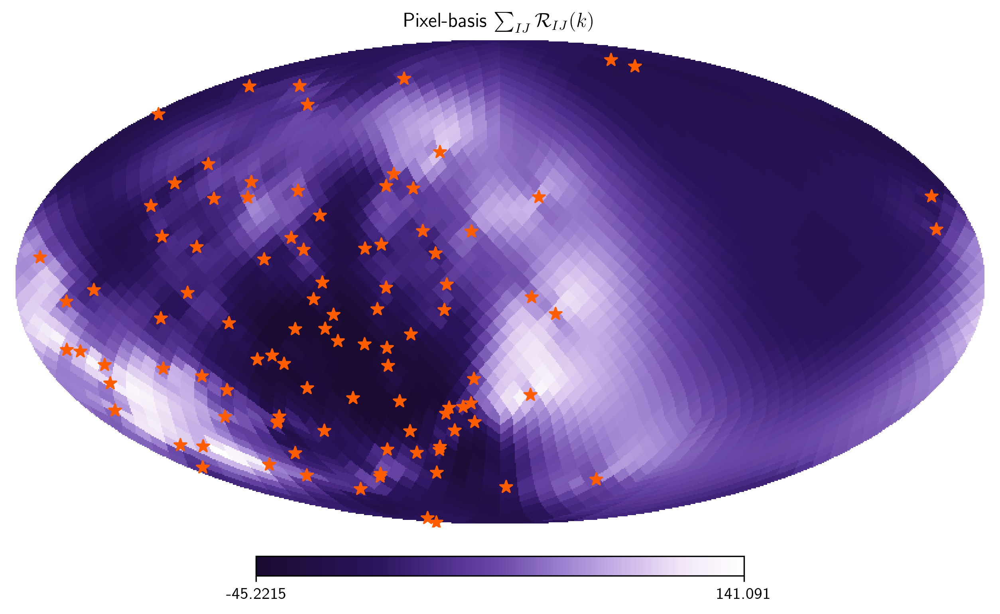

In [10]:
hp.mollview(
    np.sum(ASM.NPIX * ASM.R_IJ, axis=0),
    title=r'Pixel-basis $\sum_{IJ}\mathcal{R}_{IJ}(k)$',
    cmap="purple_cmap_r", rot=(180, 0, 0))
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=60)
plt.show()


### Individual pair responses

The full $R_{IJ}$ sum above combines all pulsar pairs. Below we show the response for two individual pairs: the closest pair on the sky (narrow, concentrated beam) and the farthest pair (broad beam).

In [11]:
# Identify the closest, farthest, and median-separation pulsar pairs.
from itertools import combinations

def angsep_rad(th1, ph1, th2, ph2):
    cosg = (np.sin(th1)*np.sin(th2)*np.cos(ph1 - ph2)
            + np.cos(th1)*np.cos(th2))
    return np.arccos(np.clip(cosg, -1.0, 1.0))

phis = np.asarray(ASM.phis)
thetas = np.asarray(ASM.thetas)
N = len(phis)

pair_idx, sep_rad = [], []
for i, j in combinations(range(N), 2):
    pair_idx.append((i, j))
    sep_rad.append(angsep_rad(thetas[i], phis[i], thetas[j], phis[j]))
pair_idx = np.array(pair_idx)
sep_rad = np.array(sep_rad)

order = np.argsort(sep_rad)
min_pair = tuple(pair_idx[order[0]])
med_pair = tuple(pair_idx[order[len(order) // 2]])
max_pair = tuple(pair_idx[order[-1]])

print(f'Closest pair:  idx={min_pair}, sep={np.degrees(sep_rad[order[0]]):.1f} deg')
print(f'Median pair:   idx={med_pair}, sep={np.degrees(sep_rad[order[len(order)//2]]):.1f} deg')
print(f'Farthest pair: idx={max_pair}, sep={np.degrees(sep_rad[order[-1]]):.1f} deg')


Closest pair:  idx=(np.int64(3), np.int64(85)), sep=0.9 deg
Median pair:   idx=(np.int64(9), np.int64(56)), sep=68.7 deg
Farthest pair: idx=(np.int64(62), np.int64(84)), sep=176.8 deg


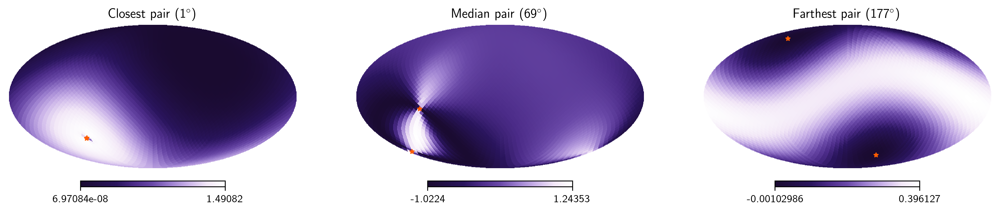

In [12]:
# Three pair responses side-by-side: closest, median, farthest separation.
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (lbl, pair) in zip(
        axes,
        [('Closest pair',  min_pair),
         ('Median pair',   med_pair),
         ('Farthest pair', max_pair)]):
    i, j = pair
    ASM_pair = haniso.Anisotropy([specs_15[i], specs_15[j]], theta_pix, phi_pix,
                                 NSIDE=NSIDE, basis='pixel')
    plt.sca(ax)
    sep_deg = np.degrees(angsep_rad(ASM_pair.thetas[0], ASM_pair.phis[0],
                                    ASM_pair.thetas[1], ASM_pair.phis[1]))
    hp.mollview(np.sum(ASM_pair.NPIX * ASM_pair.R_IJ, axis=0), 
                title=f'{lbl} ({sep_deg:.0f}' + r'$^{\circ}$)',
                cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white')
    hp.projscatter(ASM_pair.phis * 180/np.pi, 90 - ASM_pair.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=15)

plt.tight_layout()
plt.show()


## Spherical Harmonic Basis (`'sph_harm'`)

The SH basis projects the pixel response onto real spherical harmonics up to
$l_{\max}$, chosen automatically based on the number of pulsar pairs. The
response tensor has shape `(N_pairs, N_lm)` with $N_{lm} = (l_{\max} + 1)^2$.


In [13]:
# Use higher lmax for better angular resolution
# Max from pairs: (lmax+1)^2 <= Npairs; max from HEALPix: 3*NSIDE-1
Npairs = len(specs_15) * (len(specs_15) - 1) // 2
lmax_use = min(int(np.floor(np.sqrt(Npairs))) - 1, 3*NSIDE - 1, 15)
print(f'Using lmax={lmax_use} (Npairs={Npairs}, HEALPix limit={3*NSIDE-1}, tutorial cap=15)')

ASM_spharm = haniso.Anisotropy(specs_15, theta_pix, phi_pix, NSIDE=NSIDE, basis='sph_harm', lmax=lmax_use)
print(f'R_IJ_lm shape: {ASM_spharm.R_IJ.shape}  (Npairs x Nlm)')


Using lmax=15 (Npairs=4950, HEALPix limit=47, tutorial cap=15)
R_IJ_lm shape: (4950, 256)  (Npairs x Nlm)


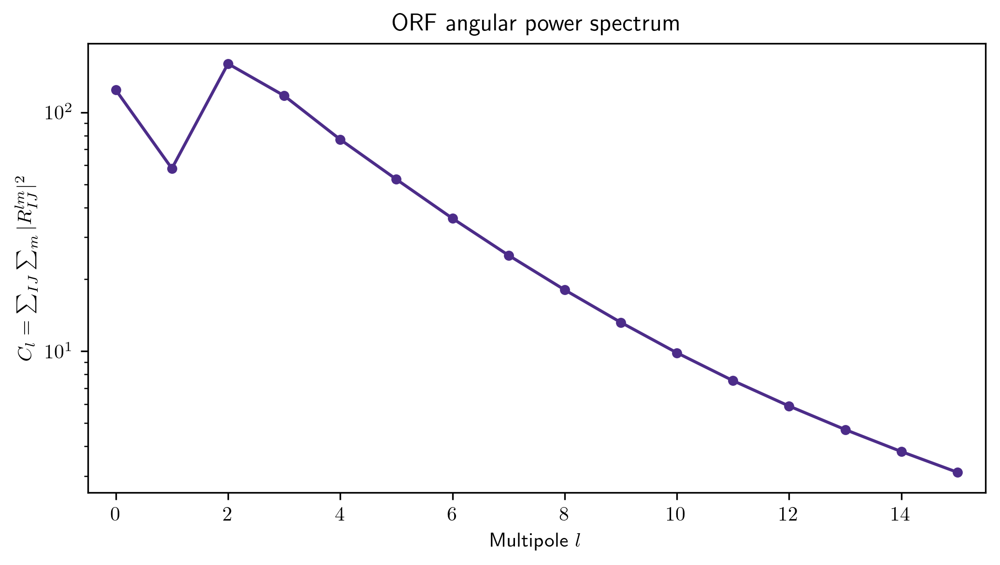

C_0 / C_total = 17.3% (monopole fraction)


In [14]:
# ORF angular power spectrum
# C_l = sum_IJ sum_m |R_IJ^lm|^2 — measures how much sensitivity lives at angular scale ~180/l deg
labels = ASM_spharm.basis_strategy.labels
R_lm_power = np.sum(ASM_spharm.R_IJ**2, axis=0)
ls = np.array([l for l, m in labels])
lmax = int(np.sqrt(len(labels))) - 1
l_unique = np.arange(lmax + 1)
Cl = np.array([R_lm_power[ls == l].sum() for l in l_unique])

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(l_unique, Cl, 'o-', color='#4C2C89', ms=4)
ax.set_xlabel('Multipole $l$')
ax.set_ylabel(r'$C_l = \sum_{IJ} \sum_m |R_{IJ}^{lm}|^2$')
ax.set_title('ORF angular power spectrum')
ax.set_xlim(-0.5, lmax + 0.5)
plt.tight_layout()
plt.show()
print(f'C_0 / C_total = {Cl[0]/Cl.sum():.1%} (monopole fraction)')


### $R_{IJ}$ — Spherical Harmonic Reconstruction

The spherical harmonic basis truncates at
$l_\mathrm{max} = \min(\lfloor\sqrt{N_\mathrm{pairs}}\rfloor - 1,\; 3 N_\mathrm{side} - 1)$.
With $N_\mathrm{side} = 16$, the HEALPix bandlimit $3 N_\mathrm{side} - 1 = 47$ is
the binding constraint. This truncation smooths sharp features in
$\mathcal{R}_{IJ}$ (especially near pulsar directions), producing small
residuals (~5–10%) at the peaks that shrink with higher $N_\mathrm{side}$.

The map below shows the SH-reconstructed $\sum_{IJ}\mathcal{R}_{IJ}(k)$ on
its own. The direct pixel-vs-SH comparison lives in the Angular Response
section below.


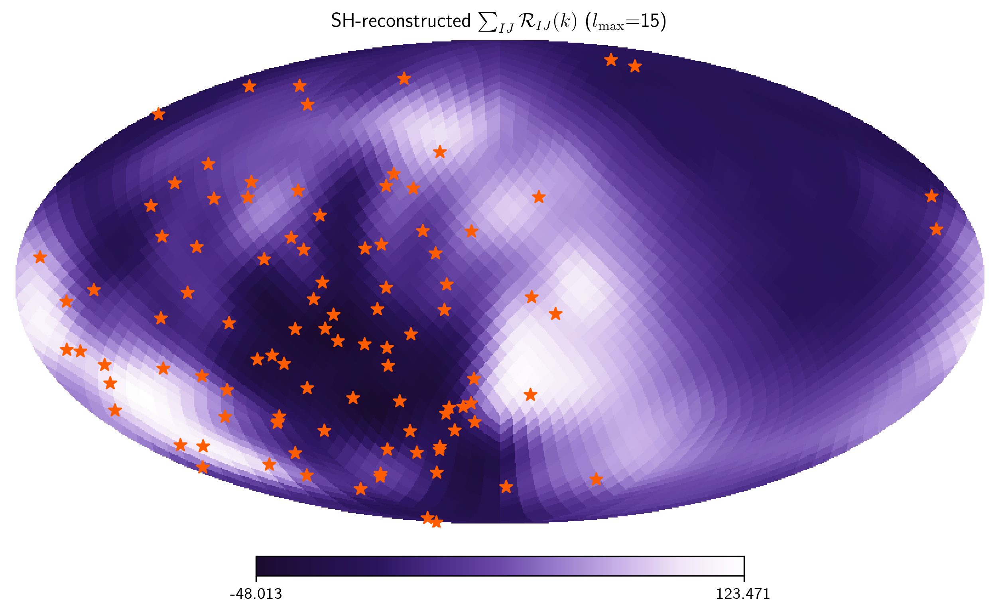

SH recon sum range: [-48.01, 123.47]


In [15]:
# Reconstruct R_IJ from spherical-harmonic coefficients back to pixel space
# and show the total sum over pairs.
lmax_sh = int(np.sqrt(ASM_spharm.R_IJ.shape[1])) - 1
Ylm, labels = ASM_spharm.basis_strategy._get_Ylm_matrix(ASM_spharm, lmax_sh)

R_geom_recon_sh = ASM_spharm.R_IJ @ Ylm       # (Npairs, Npix)
R_sum_recon = np.sum(R_geom_recon_sh, axis=0)

hp.mollview(R_sum_recon,
         title=fr'SH-reconstructed $\sum_{{IJ}}\mathcal{{R}}_{{IJ}}(k)$ '
               fr'($l_\mathrm{{max}}$={lmax_sh})',
         cmap='purple_cmap_r', rot=(180, 0, 0))
hp.projscatter(ASM_spharm.phis * 180/np.pi, 90 - ASM_spharm.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=60)
plt.show()

print(f'SH recon sum range: [{R_sum_recon.min():.2f}, {R_sum_recon.max():.2f}]')

# Free large intermediates from this cell
del R_geom_recon_sh

### Individual spherical harmonic mode

Below we show the $l=2, m=2$ basis function $Y_{22}(\hat\Omega_k)$ and the corresponding $R_{IJ}$ response summed over pairs projected onto that mode. This illustrates how a single SH mode contributes to the overall response.

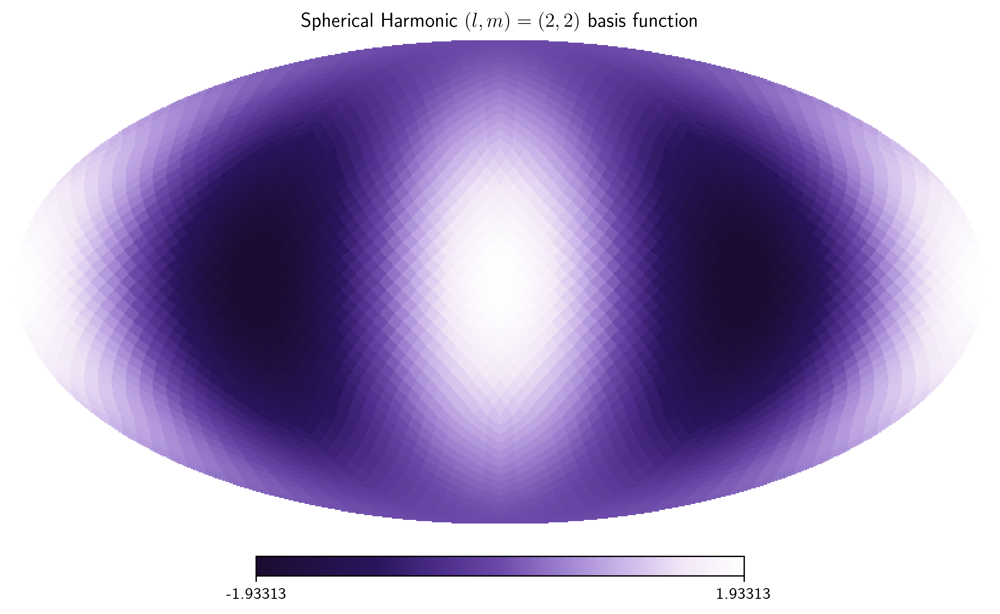

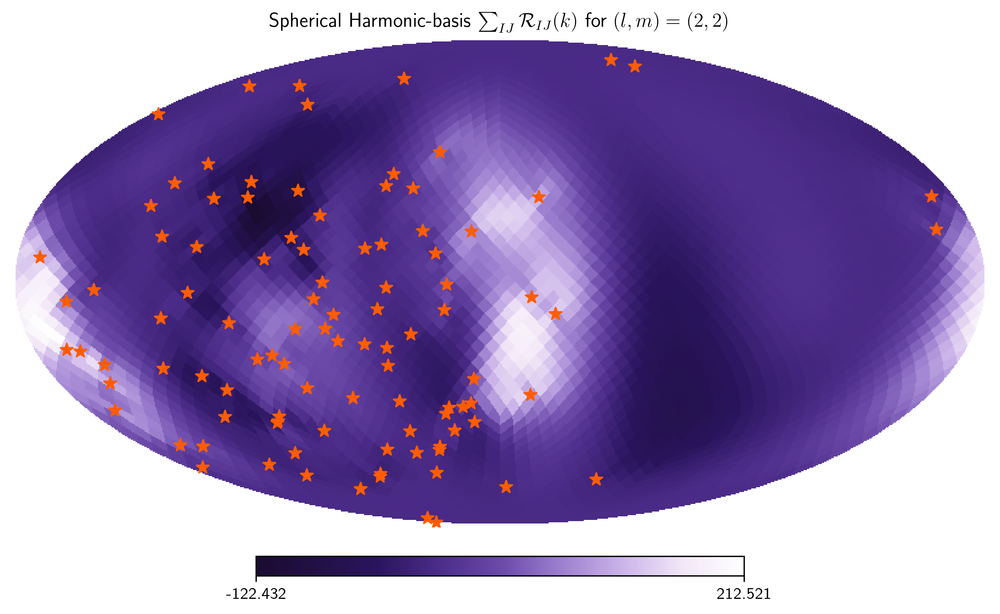

In [16]:
Y22 = Ylm[labels.index((2, 2))]

hp.mollview(
    Y22,
    title=r'Spherical Harmonic $(l,m)=(2,2)$ basis function',
    cmap='purple_cmap_r', rot=(180, 0, 0))
plt.show()

RIJ_Y22 = (ASM.NPIX * ASM.R_IJ) * Y22

hp.mollview(
    np.sum(RIJ_Y22, axis=0),
    title=r'Spherical Harmonic-basis $\sum_{IJ}\mathcal{R}_{IJ}(k)$ for $(l,m)=(2,2)$',
    cmap='purple_cmap_r', rot=(180, 0, 0))
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=60)
plt.show()

# Free large intermediates from this cell
del RIJ_Y22

## Radiometer Sky Maps

The `radiometer()` method wraps `S_clean(diag=True)` — the radiometer
per-pixel estimator under the hypothesis "GW power lives only in pixel
$k$, every other pixel is zero."  Mathematically it is the diagonal-Fisher
limit of the clean map (Grunthal+2026 Eqs. 16–20 / NANOGrav 15yr Eq. 19):
$\hat{P}_k = X_k / (T_{\mathrm{obs}} M_{kk})$ with $\sigma_k = 1/\sqrt{T_{\mathrm{obs}} M_{kk}}$ and per-pixel
SNR $= \hat{P}_k/\sigma_k$.

By construction this answers the *single-direction point-source* question;
the free-sky question (every pixel a free parameter) is answered by the
full-Fisher form below.  Cauchy–Schwarz on the positive-semidefinite $M$
forces $[M^{-1}]_{kk} \ge 1/M_{kk}$ — the gap measures inter-pixel correlation
strength, not a deficiency of the radiometer.

The examples below use `ASM.injection()` to generate test sky
distributions; the injection API is identical to the spherical-harmonic
section.

### Isotropic injection: isolating the array sensitivity

With a flat sky ($P_k$ uniform), the injection drops out of the SNR map and
the only structure comes from $M_{kk}$ — the Fisher information set by
pulsar positions and noise.

The two panels below show the true (flat) injection and the resulting
radiometer SNR at peak frequency. The SNR map is a pure
$\sqrt{M_{kk}}$ pattern: brightest near pulsars, faintest in sparsely
sampled patches of sky.


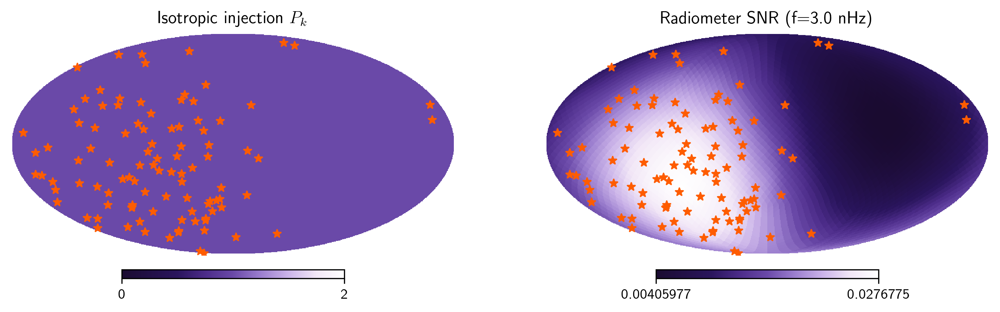

In [17]:
# Fiducial GWB amplitude — NANOGrav 15-yr best-fit (Agazie+2023)
A_gwb = 1e-15

# Isotropic injection — the SNR map is a pure sqrt(M_kk) pattern
Pk_iso_rad = np.ones(ASM.NPIX)                      # sum = NPIX (npix convention)
Sh_gwb = hsen.S_h(A=A_gwb, alpha=-2/3, freqs=ASM.freqs)
# Detection SNR per pixel per frequency (SNR_fk)
snr_iso = ASM.SNR_fk(Pk_iso_rad, Sh_gwb, diag=True)

df = np.gradient(ASM.freqs)
snr_iso = snr_iso * np.sqrt(df[:, None])

# Reference frequency (peak sensitivity)
S_eff_rad = ASM.S_eff_fk(diag=True)
fidx_pk = int(np.argmin(np.median(S_eff_rad, axis=1)))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plt.sca(axes[0])
hp.mollview(Pk_iso_rad, title=r'Isotropic injection $P_k$', 
            cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white')
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)
plt.sca(axes[1])
hp.mollview(snr_iso[fidx_pk], 
    title=f'Radiometer SNR (f={ASM.freqs[fidx_pk]*1e9:.1f} nHz)',
    cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white')
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)

plt.tight_layout()
plt.show()

# Free large intermediates from this cell
del S_eff_rad, snr_iso

### Single hotspot

A single concentrated hotspot combines the intrinsic $M_{kk}$ pattern with
an injection-driven excess at the hotspot location.


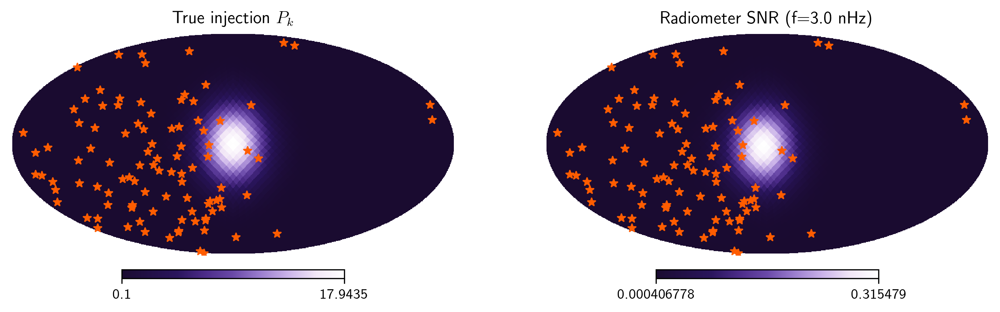

In [18]:
# Radiometer forecast: single hotspot
theta_inj, phi_inj = np.pi/2, np.pi
Pk_single, *_ = ASM.injection(
    NSIDE=ASM.NSIDE, theta=theta_inj, phi=phi_inj,
    steepness=10.0, f_iso=0.10,
)  # default normalize='npix' (so P_k sums to NPIX -- isotropic = ones)

# Detection SNR per pixel per frequency (SNR_fk)
snr_rad = ASM.SNR_fk(Pk_single, Sh_gwb, diag=True)
snr_rad = snr_rad * np.sqrt(df[:, None])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plt.sca(axes[0])
hp.mollview(Pk_single, title=r'True injection $P_k$', 
            cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white')
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)
plt.sca(axes[1])
hp.mollview(snr_rad[fidx_pk], 
    title=f'Radiometer SNR (f={ASM.freqs[fidx_pk]*1e9:.1f} nHz)',
    cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white')
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)

plt.tight_layout()
plt.show()

# Free large intermediates from this cell
del snr_rad

### Many hotspots

500 vMF hotspots with random centers and concentrations approximate a diffuse
anisotropic background. The three panels show the true injection, the
radiometer SNR at peak frequency, and the frequency-integrated SNR.


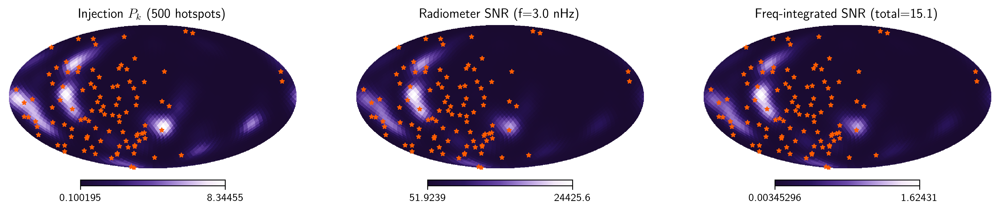

Total radiometer SNR: 15.10


In [19]:
# Radiometer forecast: many hotspots
rng_rad = np.random.default_rng(2026)
M_rad = 500
cos_t_rad = rng_rad.uniform(-1, 1, size=M_rad)
theta_rad = np.arccos(cos_t_rad)
phi_rad   = rng_rad.uniform(0, 2*np.pi, size=M_rad)
weights_rad  = rng_rad.uniform(0.1, 1.0, size=M_rad)
kappa_rad    = rng_rad.uniform(10.0, 50.0, size=M_rad)

Pk_many_rad, *_ = ASM.injection(
    NSIDE=ASM.NSIDE, theta=theta_rad, phi=phi_rad,
    amplitudes=weights_rad, steepness=kappa_rad, f_iso=0.1,
)

# Detection SNR per pixel per frequency (SNR_fk)
snr_m = ASM.SNR_fk(Pk_many_rad, Sh_gwb, diag=True)
snr_fint  = np.sqrt(np.trapezoid(snr_m**2, ASM.freqs, axis=0))
total_snr = np.sqrt(np.sum(snr_fint**2))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
plt.sca(axes[0])
hp.mollview(Pk_many_rad, title=rf'Injection $P_k$ ({M_rad} hotspots)', 
            cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white')
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=15)
plt.sca(axes[1])
hp.mollview(snr_m[fidx_pk], 
    title=f'Radiometer SNR (f={ASM.freqs[fidx_pk]*1e9:.1f} nHz)',
    cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white')
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=15)
plt.sca(axes[2])
hp.mollview(snr_fint, 
    title=f'Freq-integrated SNR (total={total_snr:.1f})',
    cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white')
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=15)

plt.tight_layout()
plt.show()

print(f'Total radiometer SNR: {total_snr:.2f}')

# Free large intermediates from this cell
del snr_m

## Square-Root Spherical Harmonic Basis

The sqrt-SH basis parameterises the map as
$P_k = \big[\sum_{LM} a_{LM}\,Y_{LM}(\hat\Omega_k)\big]^2$,
guaranteeing $P(\hat\Omega) \ge 0$ by construction — GW power is
non-negative, so this is a physically motivated parameterisation.

To show the difference between the two SH variants we use a simple test
signal: a single von Mises–Fisher hotspot generated with
`ASM.injection(theta, phi, steepness, f_iso)`. The full injection API is
documented in the Injections section; here it just supplies a peaky sky
map whose reconstruction we compare.


### Positivity enforcement

At low $l_{\max}$, the standard SH reconstruction rings below zero (Gibbs phenomenon) — unphysical for GW power. The sqrt-SH basis avoids this by squaring the amplitude field.

**Left:** True injection. **Center:** Standard SH reconstruction (negative pixels highlighted by minimum value). **Right:** Sqrt-SH reconstruction (always $\geq 0$, closer to the true shape).

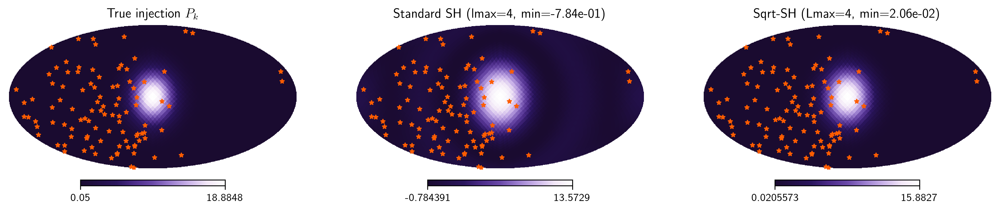

Standard SH: 1306/3072 negative pixels (min = -7.84e-01)
Sqrt-SH: 0 negative pixels by construction (min = 2.06e-02)


In [20]:
# Positivity comparison: standard SH vs sqrt-SH
Lmax_demo = 4

# Standard SH basis
ASM.set_basis('sph_harm', lmax=Lmax_demo)
Ylm_sh, labels_sh = ASM.basis_strategy._get_Ylm_matrix(ASM, ASM.basis_strategy._lmax_used)

# Sqrt-SH basis (same Lmax)
ASM.set_basis('sqrt_sph_harm', lmax=Lmax_demo)
Ylm_sqrt, labels_sqrt = ASM.basis_strategy._get_Ylm_matrix(ASM, ASM.basis_strategy._lmax_used)

# Single-hotspot injection
Pk_hot, *_ = ASM.injection(NSIDE=ASM.NSIDE, theta=np.pi/2, phi=np.pi,
                           steepness=10.0, f_iso=0.05)

# Standard SH: project and reconstruct
c_lm = (1.0 / ASM.NPIX) * (Ylm_sh @ Pk_hot)
Pk_sh_recon = Ylm_sh.T @ c_lm

# Sqrt-SH: project sqrt, reconstruct, square
a_LM, _ = ASM.basis_strategy.alm_from_Pk(ASM, Pk_hot)
Pk_sqrt_recon = ASM.basis_strategy.Pk_from_alm(ASM, a_LM)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
plt.sca(axes[0])
hp.mollview(Pk_hot, title=r'True injection $P_k$', 
            cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white')
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=15)

plt.sca(axes[1])
hp.mollview(Pk_sh_recon, 
    title=f'Standard SH (lmax={Lmax_demo}, min={Pk_sh_recon.min():.2e})',
    cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white')
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=15)

plt.sca(axes[2])
hp.mollview(Pk_sqrt_recon, 
    title=f'Sqrt-SH (Lmax={Lmax_demo}, min={Pk_sqrt_recon.min():.2e})',
    cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white')
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=15)

plt.tight_layout()
plt.show()

n_neg = np.sum(Pk_sh_recon < 0)
print(f'Standard SH: {n_neg}/{len(Pk_sh_recon)} negative pixels '
      f'(min = {Pk_sh_recon.min():.2e})')
print(f'Sqrt-SH: 0 negative pixels by construction '
      f'(min = {Pk_sqrt_recon.min():.2e})')

# Restore pixel basis for the cells that follow
ASM.set_basis('pixel')


## Principal-Map Basis

The principal-map basis (`basis='principal_map'`) expands the sky in the eigenmodes of the array's own Fisher matrix rather than in fixed coordinates ([Ali-Haïmoud+2021](https://link.aps.org/doi/10.1103/PhysRevD.103.042009)). Because the Fisher matrix is diagonal in this basis, the radiometer and full-Fisher estimators coincide, giving a single sensitivity per mode $S_{\mathrm{eff}}(f,n)=\sqrt{1/\lambda_n(f)}=\Sigma_n(f)$. The eigenvalues $\lambda_n$ fall off steeply, so only the leading modes are well constrained and the rest are noise-dominated. Below we show the eigenvalue spectrum, the per-mode sensitivity curves, and the leading principal maps on the sky. To read the two panels below: the left is the eigenvalue spectrum, ordered from the most- to least-detectable mode, and the right shows each leading mode's characteristic-strain curve $h_c(f,n)$, where a lower curve is more sensitive (so mode 0, the largest eigenvalue, sits at the bottom).

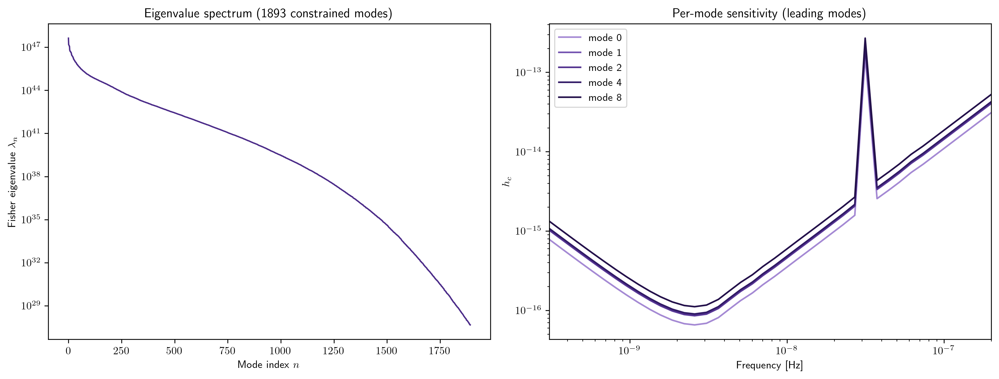

1893 constrained modes of 3072 at the peak frequency (3.01 nHz)


In [21]:
# Principal-map basis: eigenvalue spectrum and per-mode sensitivity
ASM_pm = haniso.Anisotropy(specs_15, theta_pix, phi_pix, NSIDE=NSIDE,
                           basis='principal_map', underlying='pixel')
# Evaluate the eigendecomposition at the array's peak-sensitivity frequency (defined
# from the pixel-basis S_eff, as used elsewhere in this tutorial), rather than an
# arbitrary mid-band point.
fidx_pk_pm = int(np.argmin(np.median(ASM.S_eff_fk(diag=True), axis=1)))
f_pk_pm_nHz = ASM_pm.freqs[fidx_pk_pm] * 1e9

# Fisher eigenvalues at the peak frequency (modes ordered most- to least-detectable)
lam_pm, Sig_pm = ASM_pm.principal_modes_fk(freqs_idx=[fidx_pk_pm])
lam0 = lam_pm[0]
n_constrained = int(np.sum(lam0 > 0))

# Per-mode effective sensitivity across frequency (radiometer = full-Fisher here).
# Each frequency needs its own SVD of the (N_pair x N_pix) weighted response, so we
# sample a coarse log-spaced subset of the full grid; the curves are smooth and a
# few dozen points suffice (using all 300 frequencies here is very slow).
n_sub_pm = 40
fsub_pm = np.unique(np.linspace(0, len(ASM_pm.freqs) - 1, n_sub_pm).astype(int))
f_pm = ASM_pm.freqs[fsub_pm]
S_eff_pm = ASM_pm.S_eff_pm_fk(freqs_idx=fsub_pm)   # (n_sub, K); inf for unconstrained modes
hc_pm = np.sqrt(f_pm[:, None] * S_eff_pm)

# leading modes that stay finite (constrained) at every frequency
lead = [n for n in [0, 1, 2, 4, 8]
        if n < S_eff_pm.shape[1] and np.isfinite(hc_pm[:, n]).all()]
lead_colors = purple_cmap(np.linspace(0.35, 0.85, len(lead)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: Fisher eigenvalue spectrum (steep falloff -> few constrained modes)
ax = axes[0]
ax.semilogy(np.arange(n_constrained), lam0[:n_constrained], color='#4C2C89', lw=1.3)
ax.set_xlabel('Mode index $n$')
ax.set_ylabel(r'Fisher eigenvalue $\lambda_n$')
ax.set_title(f'Eigenvalue spectrum ({n_constrained} constrained modes)')

# Right: per-mode sensitivity curves for the leading modes
ax = axes[1]
for color, n in zip(lead_colors, lead):
    ax.loglog(f_pm, hc_pm[:, n], color=color, lw=1.5, label=f'mode {n}')
ax.set_xlabel('Frequency [Hz]')
ax.set_ylabel('$h_c$')
ax.set_title('Per-mode sensitivity (leading modes)')
ax.legend(loc='upper left')
ax.set_xlim(ASM_pm.freqs[1], ASM_pm.freqs[-1])

plt.tight_layout()
plt.show()

print(f'{n_constrained} constrained modes of {len(lam0)} at the peak frequency ({f_pk_pm_nHz:.2f} nHz)')

### Principal maps on the sky

Each principal map $\hat m^{(n)}$ is a sky pattern reconstructed with `principal_map_skymap(n, fidx)`. The leading mode is a broad, mostly positive pattern over the array's best-constrained region, while higher modes are signed and increasingly structured. These modes are specific to this array and frequency, so they are not directly comparable across PTAs. The colorbar is the mode's dimensionless eigenvector amplitude $\hat m^{(n)}(\hat\Omega)$ (unit-normalized, so orthonormal across modes), not a sensitivity or SNR, so light and dark mark the positive and negative weights of the pattern rather than more or less sensitive sky. Mode 0 is nodeless and positive, while the higher modes carry $+/-$ lobes whose overall sign is arbitrary. The maps are evaluated at the array's peak-sensitivity frequency (the same convention used in the Fisher-matrix analysis below), which is $\approx 3$ nHz for this simulated array.

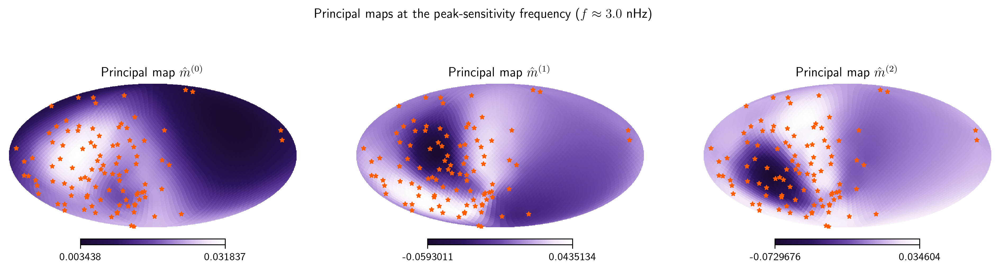

In [22]:
# Leading principal maps as sky maps (signed eigenmodes)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for i, n in enumerate([0, 1, 2]):
    m_n = ASM_pm.principal_map_skymap(n, fidx_pk_pm)
    plt.sca(axes[i])
    hp.mollview(m_n, title=rf'Principal map $\hat m^{{({n})}}$',
                cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white',
                )
    hp.projscatter(ASM_pm.phis * 180/np.pi, 90 - ASM_pm.thetas * 180/np.pi,
                   lonlat=True, marker='*', color=pulsar_color, s=15)
fig.suptitle(rf'Principal maps at the peak-sensitivity frequency ($f \approx {f_pk_pm_nHz:.1f}$ nHz)', y=1.02)
plt.tight_layout()
plt.show()

## Angular Response (Isotropic Background)

With no injected anisotropy ($P_k$ uniform over the sky) the sensitivity
maps show the PTA's intrinsic angular response — where on the sky it is
most and least sensitive, set purely by pulsar positions and noise.


For an isotropic background ($P_k = 1$ across the sky), the effective ORF $\Gamma_{IJ} = \sum_k \mathcal{R}_{IJ}(k)\,P_k$ reduces to a scaled version of the sky-averaged response, so what follows characterizes the array’s intrinsic angular sensitivity rather than any signal content. The cells below show, for both pixel and SH bases at the peak-sensitivity frequency:

- $\sum_{IJ} \mathcal{R}_{IJ}(k)$ — total ORF response per pixel, summed over pulsar pairs. Brighter regions have more pair coverage.
- $M_{kk}$ — Fisher information diagonal (raw values, log scale on the colorbar where useful). Higher = more constraining power.
- $S_{\mathrm{eff}}$ — effective strain sensitivity. Lower (lighter) = more sensitive.
- $h_c = \sqrt{f\,S_{\mathrm{eff}}}$ — characteristic-strain sensitivity.

Per-pixel sensitivity curves and the per-pixel SNR map then follow in the two cells after.

Reference freq: 3.01 nHz (index 106)


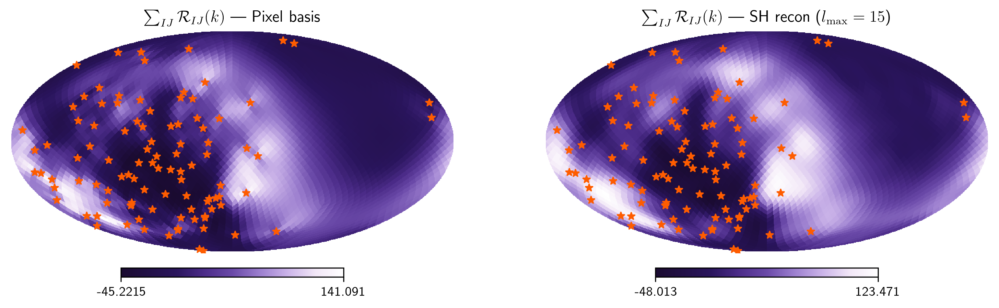

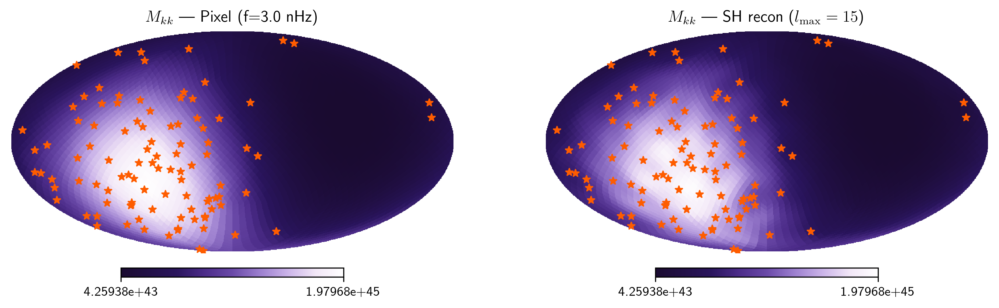

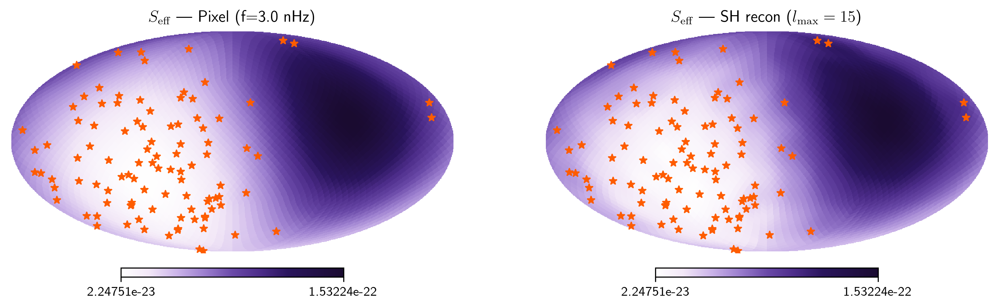

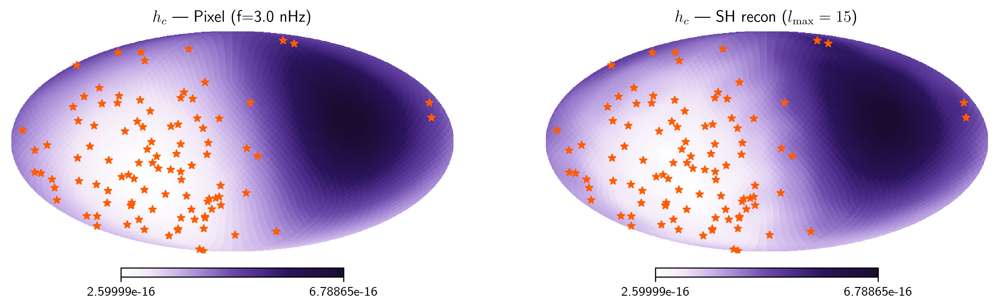

Pixel   S_eff range: [2.25e-23, 1.53e-22]
SH recon S_eff range: [2.27e-23, 1.51e-22]


53040

In [23]:
# === Isotropic sky (npix convention: sum(Pk) = NPIX) ===
NPIX = ASM.NPIX
Pk = np.ones(NPIX)                                   # isotropic, npix convention

# Reference frequency (peak sensitivity)
S_eff_pix = ASM.S_eff_fk(diag=True)
S_eff_sh  = ASM_spharm.S_eff_fk(diag=True)
min_index = int(np.argmin(np.median(S_eff_pix, axis=1)))
f_ref = ASM.freqs[min_index]
print(f'Reference freq: {f_ref*1e9:.2f} nHz (index {min_index})')

# --- R_IJ sky maps (pixel + SH reconstructed) ---
R_geom_sum = np.sum(ASM.NPIX * ASM.R_IJ, axis=0)
lmax_sh = int(np.sqrt(ASM_spharm.R_IJ.shape[1])) - 1
Ylm, _ = ASM_spharm.basis_strategy._get_Ylm_matrix(ASM_spharm, lmax_sh)
R_geom_recon = ASM_spharm.R_IJ @ Ylm
R_recon_sum = np.sum(R_geom_recon, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plt.sca(axes[0])
hp.mollview(R_geom_sum, 
    title=r'$\sum_{IJ}\mathcal{R}_{IJ}(k)$ — Pixel basis',
    cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white')
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)
plt.sca(axes[1])
hp.mollview(R_recon_sum, 
    title=fr'$\sum_{{IJ}}\mathcal{{R}}_{{IJ}}(k)$ — SH recon ($l_\mathrm{{max}}={lmax_sh}$)',
    cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white')
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)

plt.tight_layout()
plt.show()

# --- M_kk sky maps ---
M_kk_pix = ASM.Mcal(diag=True)
W_if_sh = ASM_spharm.T_IJ[:, None] / (float(ASM_spharm.Tspan) * ASM_spharm.S_IJ**2)  # T_obs folded, matches ASM.Mcal
R2_recon = R_geom_recon**2
M_kk_sh_recon = np.einsum('if,ik->fk', W_if_sh, R2_recon)
del R_geom_recon, R2_recon  # (Npair x Npix) intermediates, ~250 MB

Mkk_pix = M_kk_pix[min_index]
Mkk_sh  = M_kk_sh_recon[min_index]
vmin_m = min(Mkk_pix.min(), Mkk_sh.min())
vmax_m = max(Mkk_pix.max(), Mkk_sh.max())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plt.sca(axes[0])
hp.mollview(Mkk_pix, 
    title=fr'$M_{{kk}}$ — Pixel (f={f_ref*1e9:.1f} nHz)',
    cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white',
    min=vmin_m, max=vmax_m)
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)
plt.sca(axes[1])
hp.mollview(Mkk_sh, 
    title=fr'$M_{{kk}}$ — SH recon ($l_\mathrm{{max}}={lmax_sh}$)',
    cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white',
    min=vmin_m, max=vmax_m)
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)

plt.tight_layout()
plt.show()

# --- S_eff sky maps ---
S_eff_sh_recon = np.sqrt(np.clip(1.0 / M_kk_sh_recon, 0, None))  # folded M -> S_eff = sqrt(1/M)
vmin_s = min(S_eff_pix[min_index].min(), S_eff_sh_recon[min_index].min())
vmax_s = max(S_eff_pix[min_index].max(), S_eff_sh_recon[min_index].max())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plt.sca(axes[0])
hp.mollview(S_eff_pix[min_index], 
    title=fr'$S_\mathrm{{eff}}$ — Pixel (f={f_ref*1e9:.1f} nHz)',
    cmap='purple_cmap', rot=(180, 0, 0), hold=True, bgcolor='white',
    norm='log', min=vmin_s, max=vmax_s)
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)
plt.sca(axes[1])
hp.mollview(S_eff_sh_recon[min_index], 
    title=fr'$S_\mathrm{{eff}}$ — SH recon ($l_\mathrm{{max}}={lmax_sh}$)',
    cmap='purple_cmap', rot=(180, 0, 0), hold=True, bgcolor='white',
    norm='log', min=vmin_s, max=vmax_s)
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)

plt.tight_layout()
plt.show()

# --- h_c sky maps ---
hc_pix = np.sqrt(ASM.freqs[:, None] * S_eff_pix)
hc_sh  = np.sqrt(ASM_spharm.freqs[:, None] * S_eff_sh_recon)
vmin_h = min(hc_pix[min_index].min(), hc_sh[min_index].min())
vmax_h = max(hc_pix[min_index].max(), hc_sh[min_index].max())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plt.sca(axes[0])
hp.mollview(hc_pix[min_index], 
    title=fr'$h_c$ — Pixel (f={f_ref*1e9:.1f} nHz)',
    cmap='purple_cmap', rot=(180, 0, 0), hold=True, bgcolor='white',
    norm='log', min=vmin_h, max=vmax_h)
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)
plt.sca(axes[1])
hp.mollview(hc_sh[min_index], 
    title=fr'$h_c$ — SH recon ($l_\mathrm{{max}}={lmax_sh}$)',
    cmap='purple_cmap', rot=(180, 0, 0), hold=True, bgcolor='white',
    norm='log', min=vmin_h, max=vmax_h)
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)

plt.tight_layout()
plt.show()

print(f'Pixel   S_eff range: [{S_eff_pix[min_index].min():.2e}, {S_eff_pix[min_index].max():.2e}]')
print(f'SH recon S_eff range: [{S_eff_sh_recon[min_index].min():.2e}, {S_eff_sh_recon[min_index].max():.2e}]')

# Free large intermediates from this cell
del M_kk_pix, M_kk_sh_recon, S_eff_sh_recon, hc_pix, hc_sh
gc.collect()

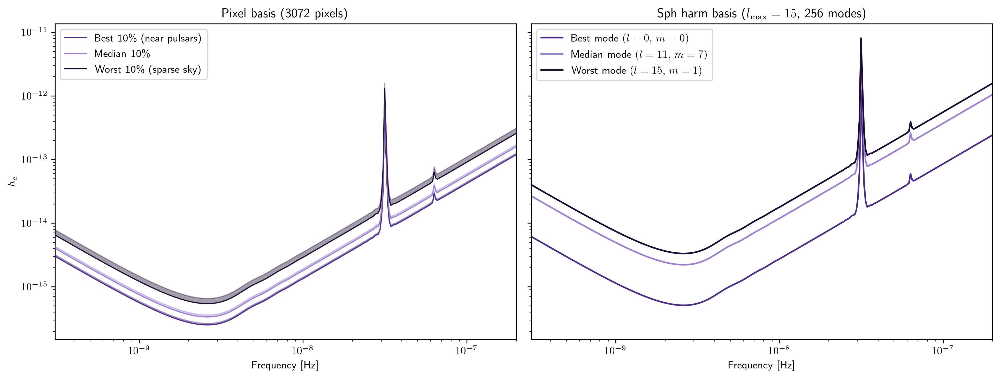

Pixel basis h_c range at peak: [9.35e-16, 2.44e-15]
Best SH mode vs best pixel: 1.90e-15 vs 9.35e-16


In [24]:
# Per-pixel / per-mode sensitivity curves (isotropic background)

fmid = len(ASM.freqs) // 2

# Pixel basis: rank pixels by S_eff at mid-frequency
order_pix = np.argsort(S_eff_pix[fmid])
n10 = max(1, int(0.10 * NPIX))
best_pix  = order_pix[:n10]
med_pix   = order_pix[NPIX//2 - n10//2 : NPIX//2 + n10//2]
worst_pix = order_pix[-n10:]

hc_pix = np.sqrt(ASM.freqs[:, None] * S_eff_pix)

# Sph harm basis: rank modes by S_eff at mid-frequency
fidx_sh = len(ASM_spharm.freqs) // 2
labels_sh = ASM_spharm.basis_strategy.labels
order_sh = np.argsort(S_eff_sh[fidx_sh])
k_best_sh, k_med_sh, k_worst_sh = order_sh[0], order_sh[len(order_sh)//2], order_sh[-1]

hc_sh = np.sqrt(ASM_spharm.freqs[:, None] * S_eff_sh)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

# Left: pixel basis
ax = axes[0]
for pix, color, label in [
    (best_pix,  '#4C2C89', r'Best 10\% (near pulsars)'),
    (med_pix,   '#9C7FCF', r'Median 10\%'),
    (worst_pix, '#1A0B30', r'Worst 10\% (sparse sky)'),
]:
    lo = hc_pix[:, pix].min(axis=1)
    hi = hc_pix[:, pix].max(axis=1)
    ax.fill_between(ASM.freqs, lo, hi, alpha=0.4, zorder=25, color=color)
    ax.loglog(ASM.freqs, lo, color=color, lw=1, label=label)
ax.set_xlabel('Frequency [Hz]')
ax.set_ylabel('$h_c$')
ax.set_title(f'Pixel basis ({NPIX} pixels)')
ax.legend(loc='upper left')
ax.set_xlim(ASM.freqs[1], ASM.freqs[-1])

# Right: sph harm basis
ax = axes[1]
for k, color, label in [
    (k_best_sh,  '#4C2C89', rf'Best mode $(l={labels_sh[k_best_sh][0]},\,m={labels_sh[k_best_sh][1]})$'),
    (k_med_sh,   '#9C7FCF', rf'Median mode $(l={labels_sh[k_med_sh][0]},\,m={labels_sh[k_med_sh][1]})$'),
    (k_worst_sh, '#1A0B30', rf'Worst mode $(l={labels_sh[k_worst_sh][0]},\,m={labels_sh[k_worst_sh][1]})$'),
]:
    ax.loglog(ASM_spharm.freqs, hc_sh[:, k], color=color, lw=1.5, label=label)
ax.set_xlabel('Frequency [Hz]')
Nlm = ASM_spharm.R_IJ.shape[1]
lmax_sh_val = int(np.sqrt(Nlm)) - 1
ax.set_title(rf'Sph harm basis ($l_\mathrm{{max}}={lmax_sh_val}$, {Nlm} modes)')
ax.legend(loc='upper left')
ax.set_xlim(ASM.freqs[1], ASM.freqs[-1])

plt.tight_layout()
plt.show()

print(f'Pixel basis h_c range at peak: [{hc_pix[fmid].min():.2e}, {hc_pix[fmid].max():.2e}]')
print(f'Best SH mode vs best pixel: {hc_sh[fidx_sh, k_best_sh]:.2e} vs {hc_pix[fmid].min():.2e}')

# Free large intermediates from this cell
del hc_pix, hc_sh

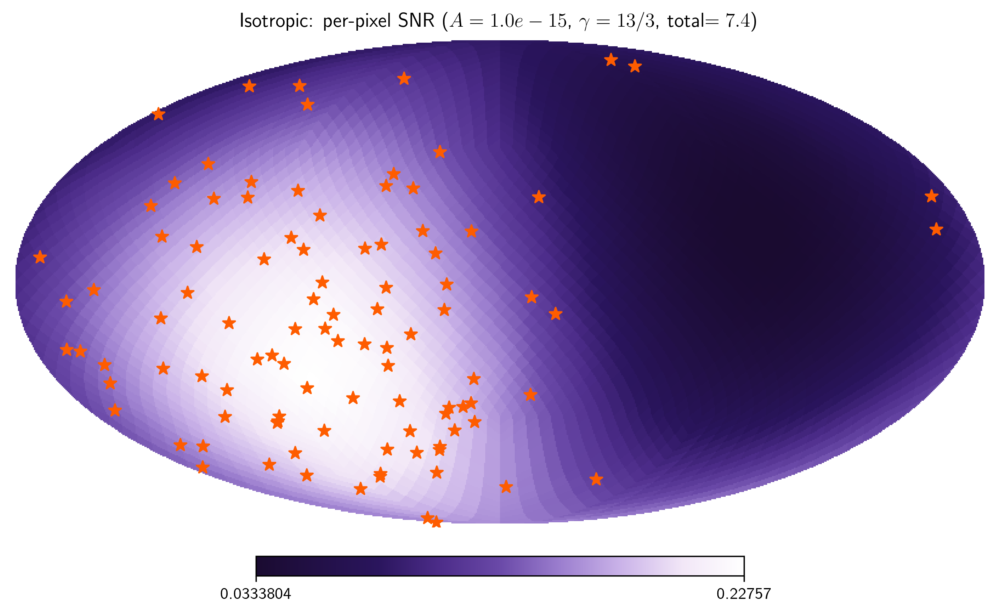

Per-pixel SNR: [0.0334, 0.2276]


In [25]:
# SNR sky map — isotropic background (npix convention: Pk = ones(NPIX))
SNR_map = ASM.SNR_fk(Pk, Sh_gwb, diag=True)         # Pk defined above
snr_fint = np.sqrt(np.trapezoid(SNR_map**2, ASM.freqs, axis=0))
total_snr = np.sqrt(np.sum(snr_fint**2))

hp.mollview(snr_fint,
    title=rf'Isotropic: per-pixel SNR ($A={A_gwb:.1e}$, $\gamma=13/3$, total$={total_snr:.1f}$)',
    cmap='purple_cmap_r', rot=(180, 0, 0))
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=60)
plt.show()
print(f'Per-pixel SNR: [{snr_fint.min():.4f}, {snr_fint.max():.4f}]')

# Free large intermediates from this cell
del SNR_map

In [26]:
Pk_iso = np.ones(ASM.NPIX)  # isotropic, npix convention
sc = hsen.GWBSensitivityCurve(specs_15)
Sh_gwb = hsen.S_h(A=A_gwb, alpha=-2/3, freqs=sc.freqs)
snr_iso_standard = sc.SNR(Sh_gwb)
snr_total, snr2_f = ASM.SNR_total(Pk_iso, Sh_gwb, diag=False)
print(f'Standard hasasia isotropic SNR (A={A_gwb:.0e}): {snr_iso_standard:.2f}')
print(f'Anisotropy module isotropic SNR (A={A_gwb:.0e}): {snr_total:.2f}')
print(f'Ratio: {snr_total / snr_iso_standard:.2f}') 

Standard hasasia isotropic SNR (A=1e-15): 169.25
Anisotropy module isotropic SNR (A=1e-15): 169.24
Ratio: 1.00


## Fisher Matrix Analysis

The radiometer uses only the diagonal $M_{kk}$ — the Cramér–Rao bound
for the single-pixel point-source hypothesis. The **full Fisher matrix**
$M_{kk'}$ captures inter-pixel correlations:

$$M_{kk'}(f) = \sum_{IJ} \frac{T_{IJ}}{T_{\mathrm{obs}}}\,\frac{\mathcal{R}_{IJ}(\hat\Omega_k)\,\mathcal{R}_{IJ}(\hat\Omega_{k'})}{S_I(f)\,S_J(f)}$$

The full-Fisher per-pixel variance under the free-sky model — every pixel
treated as a free parameter — is $\sigma_k^2 = [M^{-1}]_{kk}$. By
Cauchy–Schwarz, $[M^{-1}]_{kk} \ge 1/M_{kk}$
([Vallisneri 2008](https://arxiv.org/abs/gr-qc/0703086)): treating all
other pixels as free parameters can only inflate the variance on the one you keep.

Both estimators appear in the PTA literature for their respective
hypotheses (Grunthal+2025 §3.9). The methods
framework here exposes both via `S_eff_fk(diag=True)` (radiometer) and
`S_eff_fk(diag=False, rcond=...)` (full-Fisher). The cells below
illustrate the comparison on the simulated test array.

**Normalized Fisher correlation.** A useful diagnostic is the
*normalized* off-diagonal entry
$$\rho_{kk'} \;\equiv\; \frac{M_{kk'}}{\sqrt{M_{kk}\,M_{k'k'}}} \;\in\; [-1,\,1].$$
This is the textbook correlation between the per-pixel Fisher
information at directions $\hat\Omega_k$ and $\hat\Omega_{k'}$ (see
[Vallisneri 2008](https://arxiv.org/abs/gr-qc/0703086) for the GW-context
discussion of normalized Fisher off-diagonals). Values near 1 indicate
that the two directions' sensitivity is fully redundant — every pulsar
pair contributing to one contributes proportionally to the other; values
near 0 indicate independent information. The plot below shows
$\rho_{kk'}$ vs angular separation $\theta_{kk'}$ on the test
array.

**Note on the full-Fisher estimator:** $M$ is rank-deficient at fixed $f$,
so $[M^{-1}]_{kk}$ requires SVD regularization. The numerical magnitude
of the full-Fisher variance therefore depends on the SVD truncation
choice (`rcond`); the SVD sensitivity demo below makes this dependence
explicit. For methods-paper purposes the relevant point is that the
two estimators answer different questions; users should pick the one
matched to their search hypothesis.

### Radiometer vs full-Fisher $S_{\mathrm{eff}}$ at peak frequency

**Left:** Radiometer $S_{\mathrm{eff}}^{\rm rad} = \sqrt{1/M_{kk}}$.
The matched-filter sensitivity to a point source at $\hat k$ (used by
e.g. CW directional searches and most published anisotropy upper
limits).

**Center:** Full-Fisher $S_{\mathrm{eff}}^{\rm full} = \sqrt{[M^{-1}]_{kk}}$.
The full-Fisher per-pixel uncertainty when every other pixel is also a
free parameter (used by clean-map reconstructions). Always $\ge$ the
radiometer by Cauchy–Schwarz; the magnitude of the gap depends on the
SVD truncation choice — see the sweep below.

**Right:** Ratio $\sigma_k^{\rm full}/\sigma_k^{\rm rad}$ as illustrated
on the test array. The ratio is a code-comparison artifact rather
than a clean array property — its absolute value depends on `rcond`.

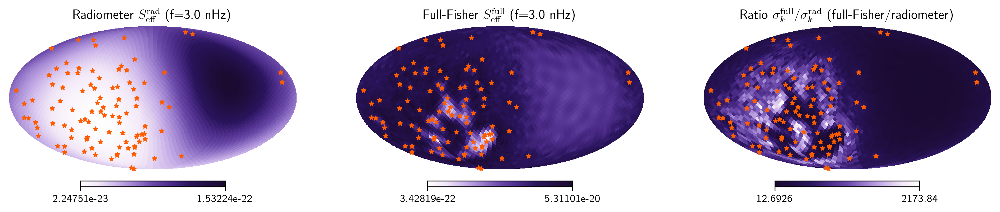

In [27]:
# Radiometer vs full-Fisher S_eff comparison
# Peak-sensitivity frequency
S_med = np.median(ASM.S_eff_fk(diag=True), axis=1)
fidx_pk = np.argmin(S_med)

# Radiometer S_eff
S_eff_rad_all = ASM.S_eff_fk(diag=True)
S_eff_rad_pk = S_eff_rad_all[fidx_pk]

# Full-Fisher S_eff at peak frequency
S_eff_full_pk = ASM.S_eff_fk(diag=False, freqs_idx=[fidx_pk])[0]

# Ratio: full-Fisher/radiometer (>= 1 everywhere by Cauchy-Schwarz)
ratio = S_eff_full_pk / np.clip(S_eff_rad_pk, 1e-30, None)
f_nHz = ASM.freqs[fidx_pk] * 1e9

fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))

plt.sca(axes[0])
hp.mollview(S_eff_rad_pk, 
    title=f'Radiometer $S_{{\\mathrm{{eff}}}}^{{\\mathrm{{rad}}}}$ (f={f_nHz:.1f} nHz)',
    cmap='purple_cmap', rot=(180, 0, 0), hold=True, bgcolor='white', norm='log')
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=15)

plt.sca(axes[1])
hp.mollview(S_eff_full_pk, 
    title=f'Full-Fisher $S_{{\\mathrm{{eff}}}}^{{\\mathrm{{full}}}}$ (f={f_nHz:.1f} nHz)',
    cmap='purple_cmap', rot=(180, 0, 0), hold=True, bgcolor='white', norm='log')
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=15)

plt.sca(axes[2])
hp.mollview(ratio, 
    title=r'Ratio $\sigma_k^{\mathrm{full}}/\sigma_k^{\mathrm{rad}}$ (full-Fisher/radiometer)',
    cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white')
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=15)

plt.tight_layout()
plt.show()

# Free large intermediates from this cell
del S_eff_rad_all

### Radiometer vs full-Fisher sensitivity curves

The Cauchy-Schwarz gap seen in the skymaps above also appears across frequency. Plotting the per-pixel sensitivity envelopes as characteristic-strain curves, the radiometer band (point-source optimal) sits *below* the isotropic `hasasia` curve, while the full-Fisher band (marginalized over the rest of the sky) sits *above* it. The two bracket the isotropic curve, the visual form of the ordering $S_{\mathrm{eff}}^{\mathrm{rad}} \le S_{\mathrm{eff}}^{\mathrm{iso}} \le S_{\mathrm{eff}}^{\mathrm{full}}$. The full-Fisher envelope is computed on a coarse frequency subset, since it requires inverting $M$ at each frequency.

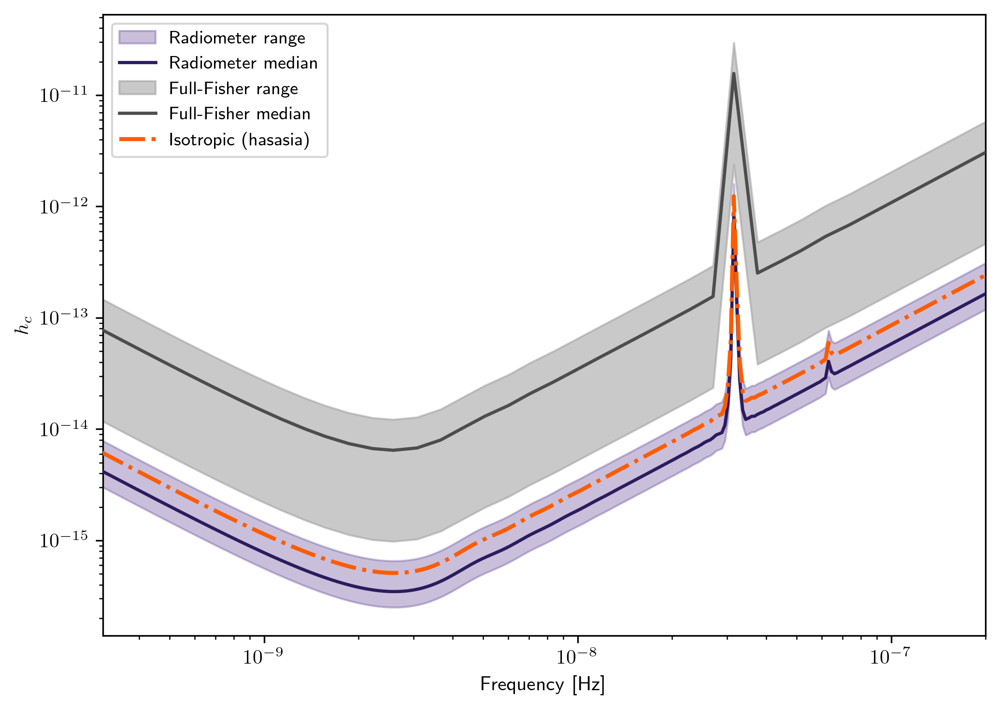

In [28]:
# Radiometer vs full-Fisher sensitivity curves: the Cauchy-Schwarz gap across frequency.
# Radiometer envelope (below) and full-Fisher envelope (above) bracket the isotropic
# hasasia curve. The radiometer uses the full grid (diagonal only, cheap); the
# full-Fisher uses a coarse frequency subset (an M inversion per frequency).

# Radiometer per-pixel h_c (full grid)
hc_rad_pix = np.sqrt(ASM.freqs[:, None] * S_eff_pix)
rad_lo, rad_hi = hc_rad_pix.min(axis=1), hc_rad_pix.max(axis=1)
rad_med = np.median(hc_rad_pix, axis=1)

# Full-Fisher per-pixel h_c on a coarse frequency subset (each frequency needs an
# M inversion, so this is the slow part; a few dozen points suffice for the curve)
n_sub = 40
fsub_idx = np.unique(np.linspace(0, len(ASM.freqs) - 1, n_sub).astype(int))
f_sub = ASM.freqs[fsub_idx]
S_eff_full_sub = ASM.S_eff_fk(diag=False, freqs_idx=fsub_idx)
hc_full_sub = np.sqrt(f_sub[:, None] * S_eff_full_sub)
full_lo, full_hi = hc_full_sub.min(axis=1), hc_full_sub.max(axis=1)
full_med = np.median(hc_full_sub, axis=1)

# Isotropic hasasia curve (same pulsars / spectra as ASM)
gwb_iso = hsen.GWBSensitivityCurve(specs_15)
hc_iso = gwb_iso.h_c

fig, ax = plt.subplots(figsize=(7, 5))
ax.fill_between(ASM.freqs, rad_lo, rad_hi, alpha=0.30, color='#4C2C89',
                zorder=2, label='Radiometer range')
ax.loglog(ASM.freqs, rad_med, color='#2D1B5E', lw=1.6, zorder=4,
          label='Radiometer median')
ax.fill_between(f_sub, full_lo, full_hi, alpha=0.55, color='#9E9E9E',
                zorder=1, label='Full-Fisher range')
ax.loglog(f_sub, full_med, color='#4D4D4D', lw=1.6, zorder=3,
          label='Full-Fisher median')
ax.loglog(gwb_iso.freqs, hc_iso, color='#FE5C00', lw=2.0, ls='-.', zorder=5,
          label='Isotropic (hasasia)')
ax.set_xlabel('Frequency [Hz]')
ax.set_ylabel('$h_c$')
ax.legend(loc='upper left', fontsize=9)
ax.set_xlim(ASM.freqs[1], ASM.freqs[-1])
plt.tight_layout()
plt.show()

# Free large intermediates from this cell
del hc_rad_pix

### Sky-weighted effective sensitivity (`S_eff_P`)

The per-direction curves above answer *"how sensitive is the array toward each direction?"* A complementary question is *"how well can the array detect **this particular sky**?"* — the **sky-weighted** effective sensitivity `S_eff_P(Pk)`, a single curve $S_{\mathrm{eff}}(f)$ for the whole sky $P(\hat\Omega)$:

$$\frac{1}{S_{\mathrm{eff}}^2(f)} = \iint \frac{d^2\hat\Omega\,d^2\hat\Omega'}{(4\pi)^2}\,P(\hat\Omega)\,\mathcal{M}(\hat\Omega,\hat\Omega';f)\,P(\hat\Omega') = \sum_{I<J}\frac{T_{IJ}}{T_{\mathrm{obs}}}\,\frac{\Gamma_{IJ}^2(f)}{S_I(f)\,S_J(f)}.$$

Unlike the per-direction curves, it carries the sky $P$ and needs no inversion of the Fisher matrix. Because it collapses the whole sky into a single spectrum, it is a **curve, not a sky map** — the sky maps below are the injected $P$ itself, shown for context. `S_eff_P` is the anisotropic generalization of the isotropic `GWBSensitivityCurve.S_eff`: for an isotropic sky ($P=1$) it reproduces the standard `hasasia` curve, and for an anisotropic sky it shifts to reflect that sky's detectability.

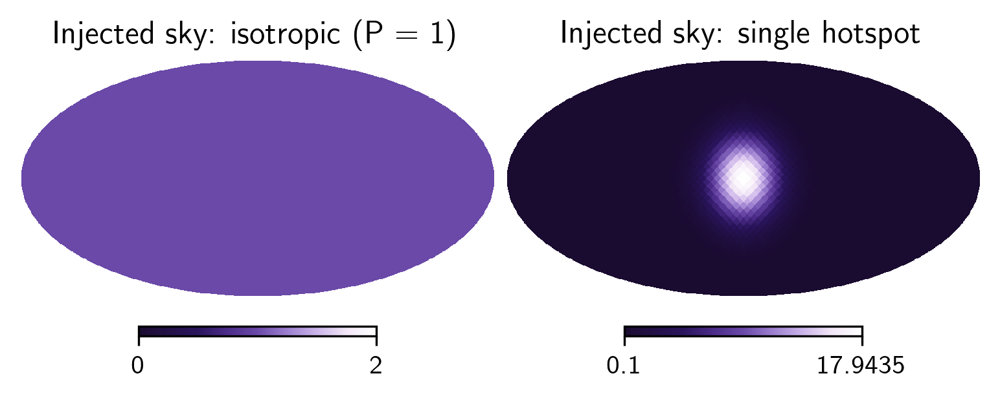

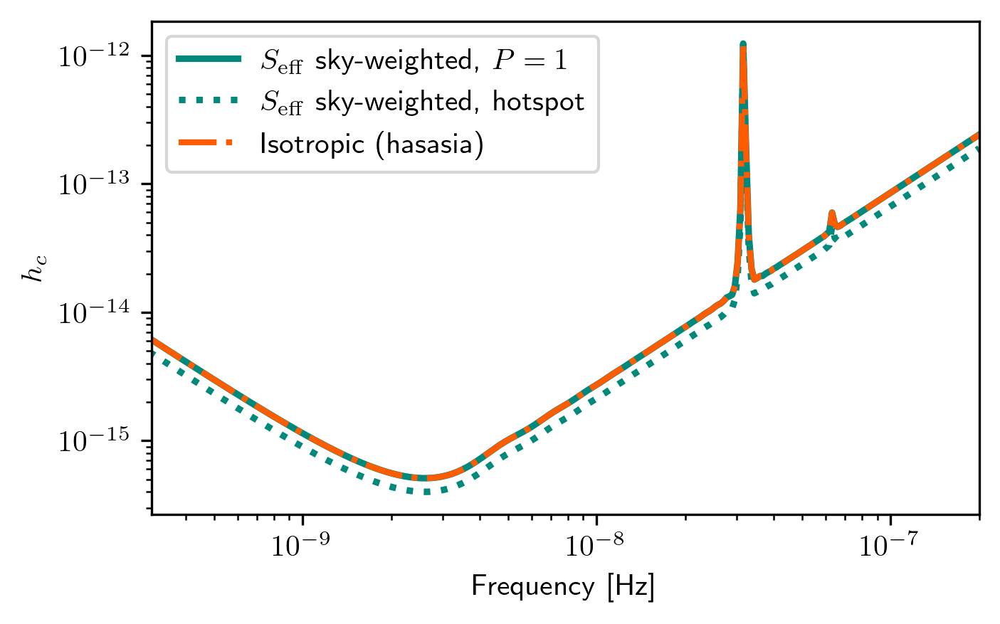

S_eff_P(P=1) vs hasasia isotropic h_c: max rel. diff = 2.95e-05


In [29]:
# Sky-weighted S_eff(f) for two skies: isotropic (P=1) and a single hotspot.
# S_eff_P returns one curve per sky (no direction index) and needs the pixel
# basis; the injected sky P is shown as a sky map only for context.
Pk_iso = np.ones(ASM.NPIX)
Pk_hotspot, *_ = ASM.injection(NSIDE=ASM.NSIDE, theta=np.pi/2, phi=np.pi,
                               steepness=10.0, f_iso=0.10)

hc_iso = np.sqrt(ASM.freqs * ASM.S_eff_P(Pk_iso))       # -> reproduces isotropic hasasia
hc_hot = np.sqrt(ASM.freqs * ASM.S_eff_P(Pk_hotspot))

# isotropic hasasia reference (same pulsars / spectra as ASM)
gwb_iso = hsen.GWBSensitivityCurve(specs_15)
hc_ref  = gwb_iso.h_c

# --- the two injected skies (context) ---
hp.mollview(Pk_iso, cmap='purple_cmap_r', rot=(180, 0, 0), sub=121,
            title='Injected sky: isotropic (P = 1)')
hp.mollview(Pk_hotspot, cmap='purple_cmap_r', rot=(180, 0, 0), sub=122,
            title='Injected sky: single hotspot')
plt.show()

# --- their whole-sky sensitivity curves ---
fig, ax = plt.subplots()
ax.loglog(ASM.freqs, hc_iso, color='#00897B', lw=2.2, ls='-',
          label=r'$S_{\mathrm{eff}}$ sky-weighted, $P=1$')
ax.loglog(ASM.freqs, hc_hot, color='#00897B', lw=2.2, ls=':',
          label=r'$S_{\mathrm{eff}}$ sky-weighted, hotspot')
ax.loglog(gwb_iso.freqs, hc_ref, color='#FE5C00', lw=2.0, ls='-.',
          label='Isotropic (hasasia)')
ax.set_xlabel('Frequency [Hz]')
ax.set_ylabel(r'$h_c$')
ax.legend()
ax.set_xlim(ASM.freqs[1], ASM.freqs[-1])
plt.show()

# built-in check: P = 1 reproduces the isotropic hasasia curve
hc_ref_i = np.interp(ASM.freqs, gwb_iso.freqs, hc_ref)
print(f'S_eff_P(P=1) vs hasasia isotropic h_c: max rel. diff = '
      f'{np.max(np.abs(hc_iso - hc_ref_i) / hc_ref_i):.2e}')

## Fisher matrix structure: pixel and SH bases

The four panels below diagnose the off-diagonal structure of the
Fisher matrix $M$ for the simulated test array at the peak sensitivity frequency,
in two complementary bases:

| **Basis** | **Absolute / raw** | **Normalized correlation** |
|---|---|---|
| **Pixel basis** | (a) $\lvert M_{kk'}\rvert$ vs $\theta_{kk'}$ (log) | (b) $\rho_{kk'} = M_{kk'}/\sqrt{M_{kk}M_{k'k'}}$ vs $\theta_{kk'}$ |
| **SH basis** | (c) $M_\ell = \sum_m M^{\ell m}_{\ell m}$ vs $\ell$ (log) | (d) $\rho_{\ell\ell'} = \|M^{\ell,\ell'}\|_F / \sqrt{\|M^{\ell,\ell}\|_F\,\|M^{\ell',\ell'}\|_F}$ heatmap |

The left column ((a), (c)) shows the **absolute scale** of the Fisher
information --- $|M_{kk'}|$ spans 5+ orders across pixel pairs and
$M_\ell$ spans $\sim 3$ orders across multipoles.  The right column
((b), (d)) collapses each onto a 0--1 correlation diagnostic that
reveals the **structure** of the inter-mode coupling.  Reading the
right column:

- (b) decays from 1 at small $\theta$ down toward 0 by $\theta \sim
  60^\circ$ and rises slightly at the antipode --- the array's
  angular response width.
- (d) shows broad off-diagonal support: even widely separated
  multipoles couple at $\sim 0.4$--$0.5$, meaning the SH basis is
  not near-diagonal for this array's Fisher matrix.  The lighter
  bottom row/left column at $\ell, \ell' \in \{0, 1\}$ reflects the
  Hellings--Downs symmetry: pulsar timing has weak dipole sensitivity,
  so $\ell = 1$ decouples from everything because the array barely
  sees it.

This is also the geometric reason the full-Fisher estimator
$\sqrt{[M^{-1}]_{kk}}$ differs from the radiometer estimator
$1/\sqrt{M_{kk}}$: the off-diagonal support in $M$ means pixels
are not independent measurements, and the inverse mixes them.

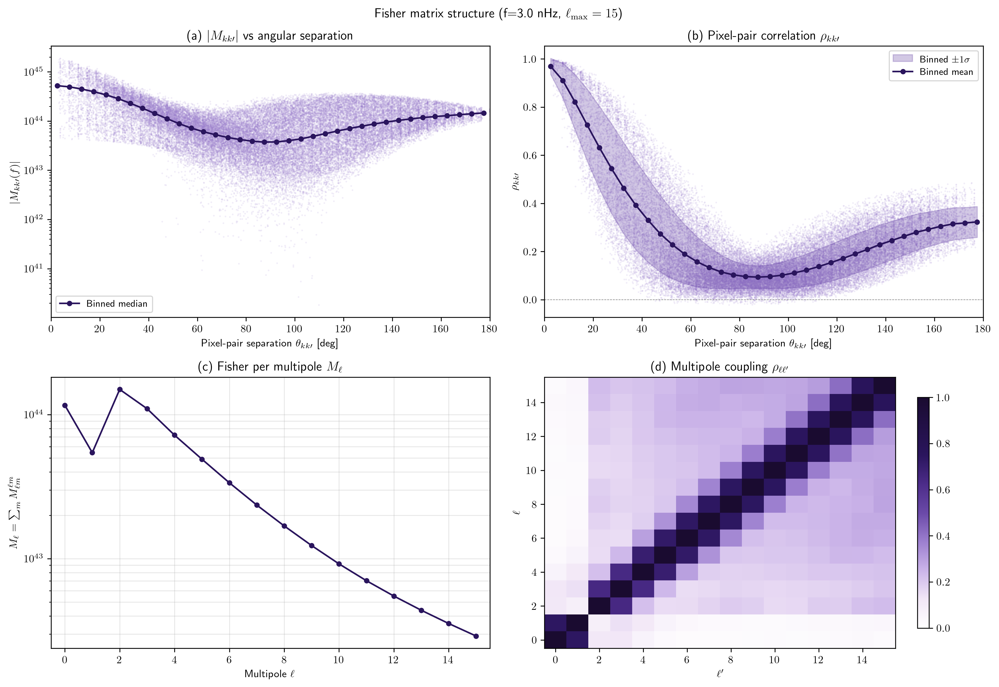

56828

In [30]:
# Full Fisher matrix at peak frequency, in pixel and SH bases.

# --- Pixel basis ---
M_full_pk = ASM.Mcal(diag=False, freqs_idx=[fidx_pk])[0]
NPIX = ASM.NPIX
pix_theta, pix_phi = hp.pix2ang(ASM.NSIDE, np.arange(NPIX))
pix_vec = hp.ang2vec(pix_theta, pix_phi)
cos_sep = np.clip(pix_vec @ pix_vec.T, -1, 1)
ang_sep_pix = np.degrees(np.arccos(cos_sep))
del pix_vec, cos_sep  # (Npix x Npix) geometry intermediates

iu = np.triu_indices(NPIX, k=1)
M_off = M_full_pk[iu]
theta_off = ang_sep_pix[iu]
M_diag = np.diag(M_full_pk)
rho_kk = M_off / np.sqrt(M_diag[iu[0]] * M_diag[iu[1]])

rng_plot = np.random.default_rng(42)
n_plot = min(50000, len(M_off))
idx_sub = rng_plot.choice(len(M_off), n_plot, replace=False)

bins_off = np.arange(0, 181, 5)
bc_off = 0.5 * (bins_off[:-1] + bins_off[1:])
mean_rho = np.zeros(len(bc_off))
std_rho = np.zeros(len(bc_off))
median_absM = np.zeros(len(bc_off))
for bi in range(len(bc_off)):
    mask = (theta_off >= bins_off[bi]) & (theta_off < bins_off[bi+1])
    if mask.any():
        mean_rho[bi] = rho_kk[mask].mean()
        std_rho[bi] = rho_kk[mask].std()
        median_absM[bi] = np.median(np.abs(M_off[mask]))

# --- SH basis ---
labels_sh = ASM_spharm.basis_strategy.labels
ls_sh = np.array([l for l, m in labels_sh])
lmax_sh = int(np.sqrt(len(labels_sh))) - 1
M_lm = ASM_spharm.Mcal(diag=False, freqs_idx=[fidx_pk])[0]
M_lm_diag = np.diag(M_lm)
M_ell = np.array([M_lm_diag[ls_sh == l].sum()
                  for l in range(lmax_sh + 1)])

ell_arr = np.arange(lmax_sh + 1)
block_norm = np.zeros((lmax_sh + 1, lmax_sh + 1))
for li in ell_arr:
    rows = (ls_sh == li)
    for lj in ell_arr:
        cols = (ls_sh == lj)
        block_norm[li, lj] = np.linalg.norm(M_lm[np.ix_(rows, cols)])

diag_block_norm = np.sqrt(np.diag(block_norm))
denom = np.outer(diag_block_norm, diag_block_norm)
denom[denom == 0] = np.nan
rho_ll = block_norm / denom

# --- 2x2 figure ---
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# (a) |M_kk'| log
ax = axes[0, 0]
ax.scatter(theta_off[idx_sub], np.abs(M_off[idx_sub]), s=0.5, alpha=0.1,
           color='#9C7FCF', rasterized=True, zorder=1)
ax.semilogy(bc_off, median_absM, 'o-', color='#2A155D', ms=4, lw=1.5,
            label='Binned median', zorder=3)
ax.set_xlabel(r'Pixel-pair separation $\theta_{kk\prime}$ [deg]')
ax.set_ylabel(r'$|M_{kk\prime}(f)|$')
ax.set_title(r'(a) $|M_{kk\prime}|$ vs angular separation')
ax.set_xlim(0, 180)
ax.legend(fontsize=9, loc='lower left')

# (b) rho_kk'
ax = axes[0, 1]
ax.scatter(theta_off[idx_sub], rho_kk[idx_sub], s=0.5, alpha=0.1,
           color='#9C7FCF', rasterized=True, zorder=1)
ax.fill_between(bc_off, mean_rho - std_rho, mean_rho + std_rho,
                alpha=0.3, color='#6A49A8', zorder=2,
                label=r'Binned $\pm 1\sigma$')
ax.plot(bc_off, mean_rho, 'o-', color='#2A155D', ms=4, lw=1.5,
        label='Binned mean', zorder=3)
ax.axhline(0, color='gray', ls='--', lw=0.5)
ax.set_xlabel(r'Pixel-pair separation $\theta_{kk\prime}$ [deg]')
ax.set_ylabel(r'$\rho_{kk\prime}$')
ax.set_title(r'(b) Pixel-pair correlation $\rho_{kk\prime}$')
ax.set_xlim(0, 180)
ax.legend(fontsize=9, loc='upper right')

# (c) M_l
ax = axes[1, 0]
ax.semilogy(ell_arr, M_ell, 'o-', color='#2A155D', ms=4, lw=1.5)
ax.set_xlabel(r'Multipole $\ell$')
ax.set_ylabel(r'$M_\ell = \sum_m M^{\ell m}_{\ell m}$')
ax.set_title(r'(c) Fisher per multipole $M_\ell$')
ax.set_xlim(-0.5, lmax_sh + 0.5)
ax.grid(alpha=0.3, which='both')

# (d) rho_ll' heatmap
ax = axes[1, 1]
im = ax.imshow(rho_ll, origin='lower', cmap='purple_cmap',
               vmin=0, vmax=1, aspect='auto',
               extent=[-0.5, lmax_sh + 0.5, -0.5, lmax_sh + 0.5])
ax.set_xlabel(r'$\ell^\prime$')
ax.set_ylabel(r'$\ell$')
ax.set_title(r'(d) Multipole coupling $\rho_{\ell\ell^\prime}$')
fig.colorbar(im, ax=ax, shrink=0.85)

fig.suptitle(f'Fisher matrix structure  (f={ASM.freqs[fidx_pk]*1e9:.1f} nHz, '
             f'$\\ell_\\mathrm{{max}}={lmax_sh}$)')
plt.tight_layout()
plt.show()

# Free large intermediates from this cell
del M_full_pk, ang_sep_pix, iu, M_off, theta_off, rho_kk, M_diag
gc.collect()

### SVD regularization (caveat)

The full-Fisher per-pixel variance $[M^{-1}]_{kk}$ requires regularization
because $M$ is rank-deficient at fixed $f$ (only $\sim N_{\rm pair}/2$
independent modes survive after pulsar pairing). We use SVD truncation
of the pseudoinverse: the singular value decomposition factorizes
$M = U \Sigma U^\top$, and the parameter `rcond` is the relative
threshold below which singular values are treated as zero before
inversion. Specifically, for each singular value $s_i$ of $M$, we set
$s_i^{-1} = 0$ whenever $s_i < \mathrm{rcond} \times s_\mathrm{max}$.
Modes with very small singular values are poorly constrained by the
pair geometry, so including them in $M^{-1}$ amplifies numerical
noise; the threshold drops them.

The numerical magnitude of the full-Fisher estimator therefore depends on
the choice of `rcond`. For methods-paper purposes the practical
guidance is: pick `rcond` based on physical considerations (e.g.,
$N_\mathrm{cutoff}$ matched to $\ell_\mathrm{eff}$, in the spirit of
Grunthal+2025 §3.7) rather than rely on a single default. The cell
below illustrates the dependence by evaluating the full-Fisher estimator
at two `rcond` values on the same array.

In [31]:
# Quick demonstration: full-Fisher S_eff depends on SVD rcond
S_eff_rad_pk_demo = ASM.S_eff_fk(diag=True)[fidx_pk]

for rc in (1e-10, 1e-8):
    S_full = ASM.S_eff_fk(diag=False, freqs_idx=[fidx_pk], rcond=rc)[0]
    ratio = S_full / np.clip(S_eff_rad_pk_demo, 1e-30, None)
    print(f'rcond={rc:.0e}:  median ratio = {np.median(ratio):6.1f}x  '
          f'(range [{ratio.min():.1f}x, {ratio.max():.1f}x])')
print('--> The full-Fisher estimator is regularization-dependent; '
      'choose rcond physically.')

rcond=1e-10:  median ratio =  332.4x  (range [12.7x, 2173.8x])
rcond=1e-08:  median ratio =   38.7x  (range [3.0x, 241.0x])
--> The full-Fisher estimator is regularization-dependent; choose rcond physically.


## Clean Map Using the NG15 GWB Amplitude and γ

The `S_clean()` method reports per-pixel uncertainty and SNR under both estimator hypotheses introduced earlier:
- **Radiometer** — each pixel treated as the only non-zero sky element (single-pixel point-source hypothesis).
- **Full-Fisher** — every pixel is a free parameter (free-sky reconstruction); exploits inter-pixel correlations.

The clean-map estimator $(\hat P_k,\,\sigma_k)$ yields, at each sky
direction $\hat\Omega_k$, a point estimate of the GWB power $\hat P_k$
and its 1$\sigma$ uncertainty $\sigma_k$.  Below we plot $\sigma_k$
under the **radiometer** and **full-Fisher**
estimators, and the per-pixel SNR $\hat P_k/\sigma_k$ (the same
radiometer/full-Fisher distinction introduced in the Fisher Matrix Analysis
section).  An isotropic injection $P_k = 1$ illustrates the array's
bare angular response — the structure on the sky is set by pulsar
distribution and pair-beam geometry, not by the injection.

The GWB amplitude used for $S_h(f)$ is the NANOGrav 15-yr best-fit
value $A = 2.4\times 10^{-15},\,\gamma = 13/3$.  The array itself is
the simulated test array, not NG15 data — the NG15 amplitude just sets a
realistic scale for $S_h(f)$.

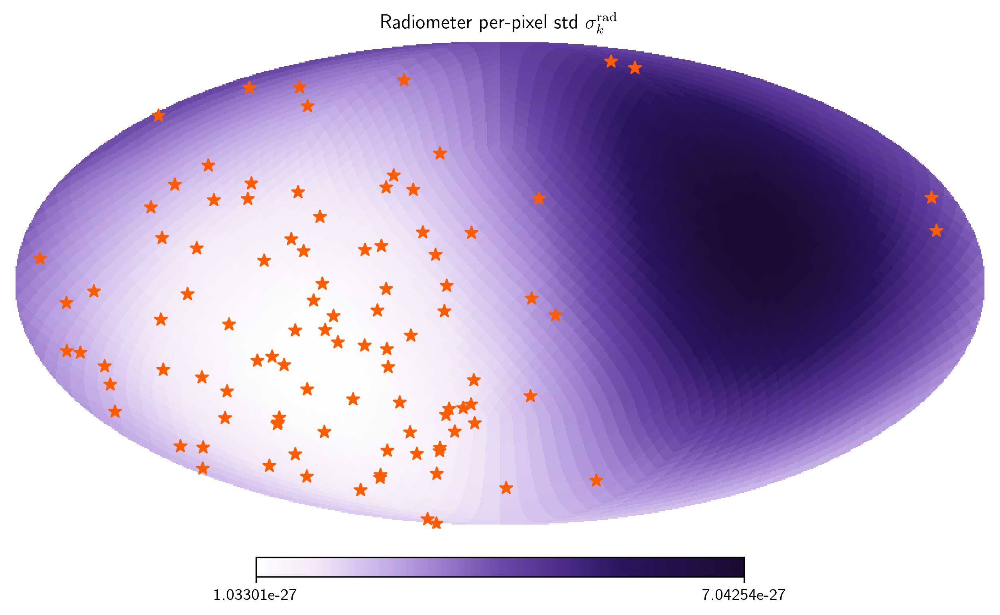

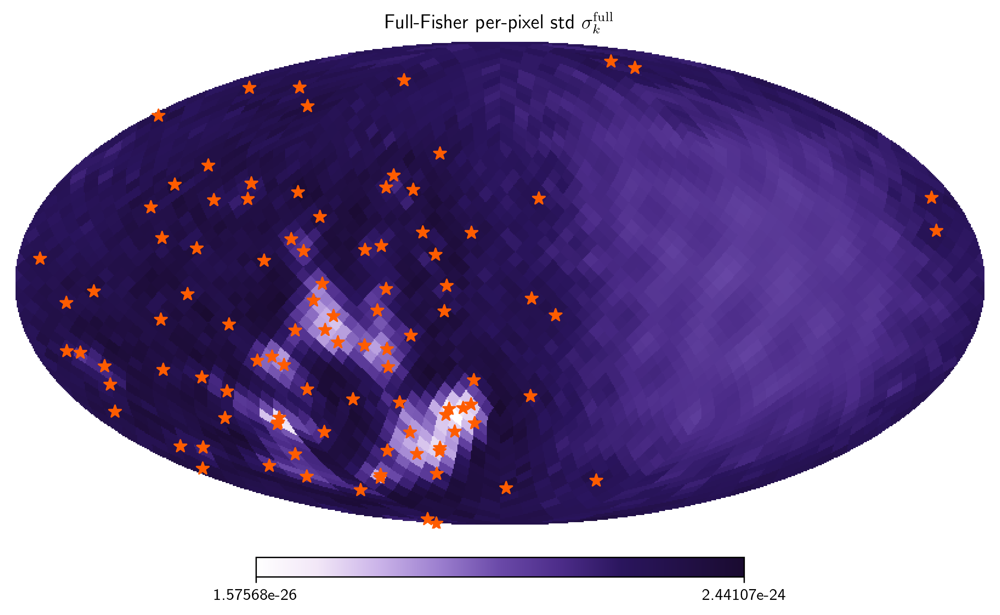

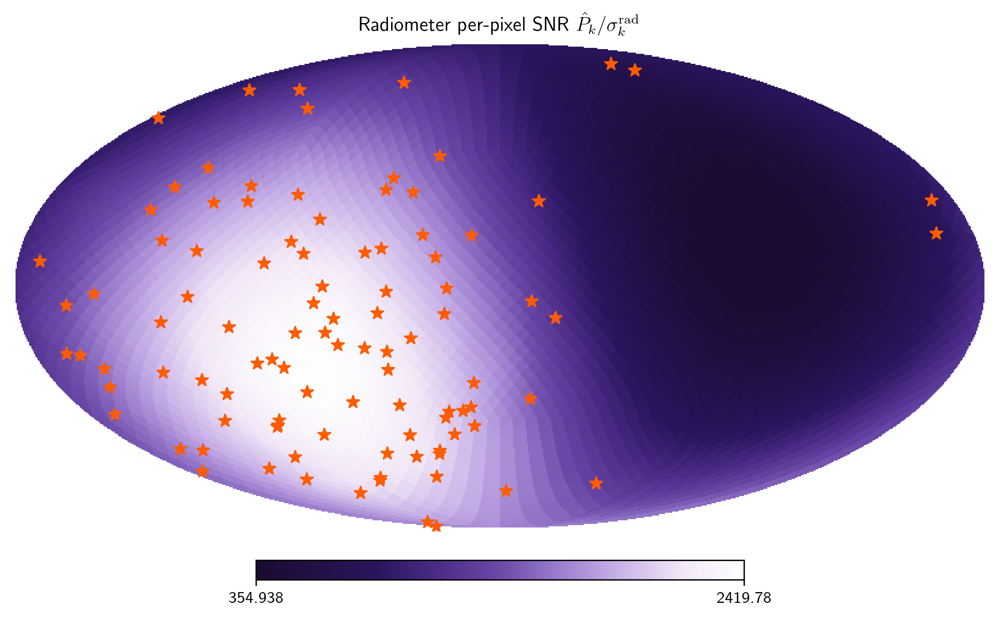

Radiometer  sigma range: [1.03e-27, 7.04e-27]
Full-Fisher sigma range: [1.58e-26, 2.44e-24]
Radiometer  SNR range:   [354.94, 2419.78]


In [32]:
# S_clean sky map — isotropic injection (Pk = 1) with NG15 GWB amplitude
# (array is the simulated test config; NG15 supplies only the GWB amplitude scale)
from matplotlib.colors import LogNorm

Pk_iso = np.ones(ASM.NPIX)

# Radiometer clean map
P_clean_rad, sigma_rad, snr_rad = ASM.S_clean(Pk_iso, Sh_gwb, diag=True)
sigma_rad_pk = sigma_rad[fidx_pk]
snr_rad_pk = snr_rad[fidx_pk]

# Full-Fisher clean map
P_clean_full, sigma_full, snr_full = ASM.S_clean(Pk_iso, Sh_gwb, diag=False,
                                                  freqs_idx=[fidx_pk])
sigma_full_pk = sigma_full[0]
snr_full_pk = snr_full[0]

# Plot: radiometer per-pixel uncertainty (LogNorm — colorbar shows 10^-N natively)
hp.mollview(sigma_rad_pk, cmap='purple_cmap',
         title=r'Radiometer per-pixel std $\sigma_k^{\mathrm{rad}}$',
         norm='log', rot=(180, 0, 0))
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=60)
plt.show()

# Plot: full-Fisher per-pixel uncertainty
hp.mollview(sigma_full_pk, cmap='purple_cmap',
         title=r'Full-Fisher per-pixel std $\sigma_k^{\mathrm{full}}$',
         norm='log', rot=(180, 0, 0))
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=60)
plt.show()

# Plot: radiometer per-pixel SNR (= P_k_hat / sigma_k)
hp.mollview(snr_rad_pk, cmap='purple_cmap_r',
         title=r'Radiometer per-pixel SNR $\hat P_k / \sigma_k^{\mathrm{rad}}$', rot=(180, 0, 0))
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=60)
plt.show()

print(f'Radiometer  sigma range: [{sigma_rad_pk.min():.2e}, {sigma_rad_pk.max():.2e}]')
print(f'Full-Fisher sigma range: [{sigma_full_pk.min():.2e}, {sigma_full_pk.max():.2e}]')
print(f'Radiometer  SNR range:   [{snr_rad_pk.min():.2f}, {snr_rad_pk.max():.2f}]')

# Free large intermediates from this cell
del P_clean_rad, sigma_rad, snr_rad

## Injections

The `injection()` method generates sky power distributions $P_k$ from
[von Mises–Fisher](https://en.wikipedia.org/wiki/Von_Mises%E2%80%93Fisher_distribution)
(vMF) mixtures:

$$P_k = f_{\mathrm{iso}}\,\frac{1}{N_{\mathrm{pix}}} + (1 - f_{\mathrm{iso}})
        \sum_i w_i\,\mathrm{vMF}_i(\hat\Omega_k;\,\mu_i,\,\kappa_i)$$

Key parameters:
- `theta, phi` — hotspot centers (colatitude, longitude in radians)
- `steepness` ($\kappa$) — vMF concentration. Higher = narrower. Typical: 5–20.
- `amplitudes` — relative weights per hotspot
- `f_iso` — isotropic floor fraction (0 = pure hotspots, 1 = isotropic)
- `normalize` — `'npix'` (default, literature convention: $\sum_k P_k = N_{\mathrm{pix}}$)
  or `'prob'` ($\sum_k P_k = 1$). Both `SNR_fk` and `S_clean` accept either
  convention via the same `normalize` kwarg.

The effective ORF for an injection is
$\Gamma_{IJ} = \sum_k \mathcal{R}_{IJ}(k)\,P_k$.

### Single Hotspot


A single vMF hotspot at $(\theta, \phi) = (\pi/2, \pi)$ with 10% isotropic floor.

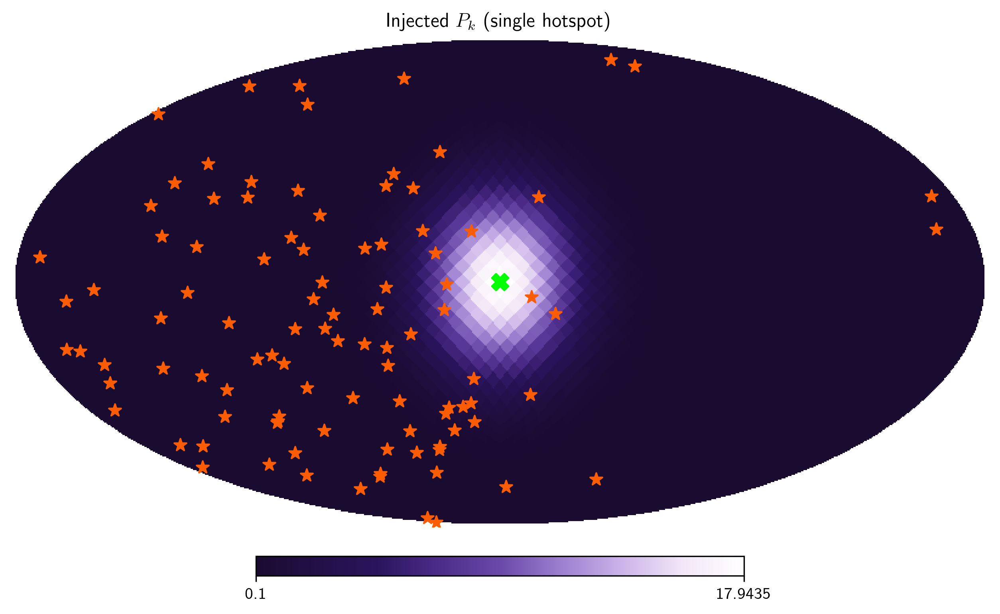

In [33]:
# Single hotspot injection (npix normalization is the default)
theta_inj, phi_inj = np.pi/2, np.pi
Pk_single, *_ = ASM.injection(
    NSIDE=ASM.NSIDE, theta=theta_inj, phi=phi_inj,
    steepness=10.0, f_iso=0.10,
)

# Effective ORF per pulsar pair (for the HD plot below)
Gamma_single = ASM.basis_strategy.pixel_orf(Pk_single)
Gamma_iso    = ASM.basis_strategy.pixel_orf(np.ones(ASM.NPIX))
ang_sep_pairs = np.degrees(np.arccos(np.clip(ASM.cosThetaIJ, -1, 1)))

hp.mollview(Pk_single, title=r'Injected $P_k$ (single hotspot)',
         cmap='purple_cmap_r', rot=(180, 0, 0))
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=60)
hp.projscatter([np.degrees(phi_inj)], [90 - np.degrees(theta_inj)],
    lonlat=True, marker='X', color='lime', s=100, zorder=5)
plt.show()


### Per-pixel SNR

The SNR sky map shows where on the sky this single hotspot is most detectable, modulated by the array’s angular sensitivity.

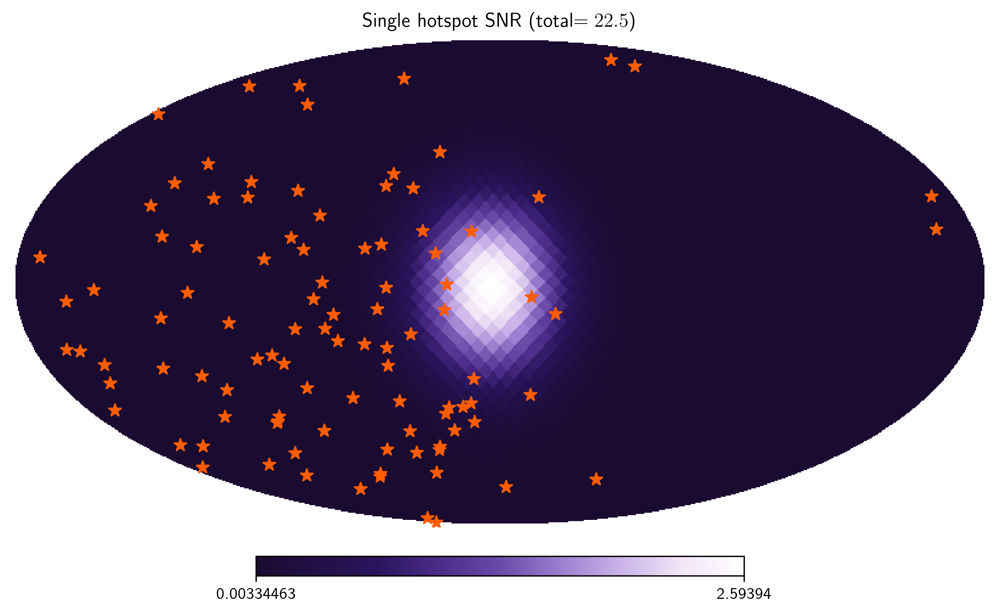

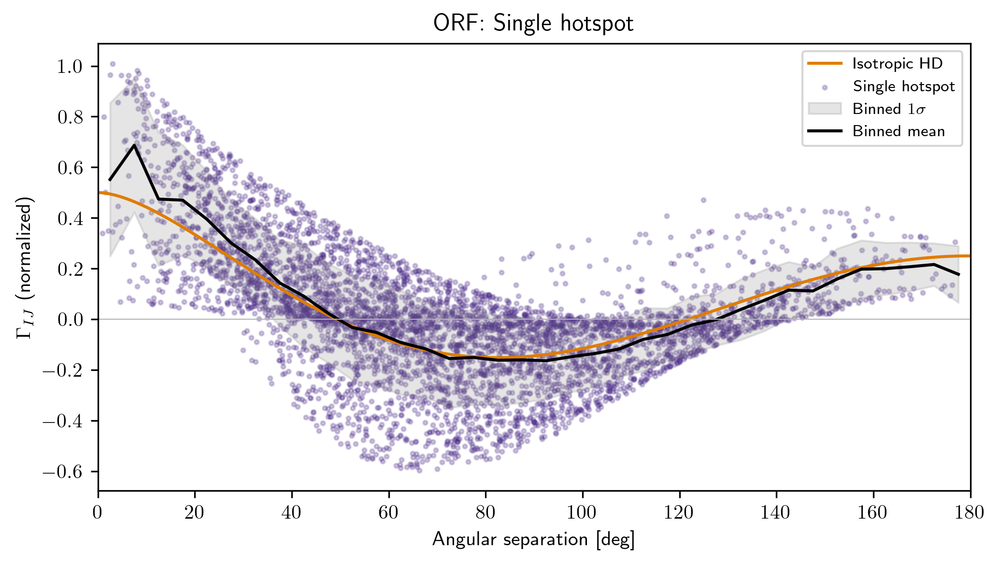

In [34]:
# Per-pixel SNR — Single hotspot
SNR_single = ASM.SNR_fk(Pk_single, Sh_gwb, diag=True)
snr_single_fint = np.sqrt(np.trapezoid(SNR_single**2, ASM.freqs, axis=0))
total_snr_single = np.sqrt(np.sum(snr_single_fint**2))

hp.mollview(snr_single_fint,
    title=rf'Single hotspot SNR (total$={total_snr_single:.1f}$)',
    cmap='purple_cmap_r', rot=(180, 0, 0))
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=60)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
# HD analytic curve
x_hd = np.linspace(0, 180, 400)
cos_hd = np.cos(np.radians(x_hd))
hd = 1.5 * ((1 - cos_hd)/2 * np.log((1 - cos_hd)/2 + 1e-30) - (1 - cos_hd)/12) + 0.5

# Normalise the injection ORF so its envelope matches the iso curve
scale = 0.5 / max(np.max(np.abs(Gamma_iso)), 1e-30)
g_inj = Gamma_single * scale
bc, bm, lo, hi = haniso.binned_stats(ang_sep_pairs, g_inj, bins=np.arange(0, 181, 5))

ax.plot(x_hd, hd, '-', color='#E07C00', lw=1.5, label='Isotropic HD')
ax.scatter(ang_sep_pairs, g_inj, s=4, alpha=0.25, color='#4C2C89', label='Single hotspot')
ax.fill_between(bc, lo, hi, color='0.5', alpha=0.2, label=r'Binned $1\sigma$')
ax.plot(bc, bm, '-', color='k', lw=1.5, label='Binned mean')
ax.axhline(0, color='0.7', lw=0.5)
ax.set_xlabel('Angular separation [deg]')
ax.set_ylabel(r'$\Gamma_{IJ}$ (normalized)')
ax.set_title('ORF: Single hotspot')
ax.set_xlim(0, 180)
ax.legend(fontsize=8, loc='best')
plt.tight_layout()
plt.show()

# Free large intermediates from this cell
del SNR_single

### Two Hotspots: Symmetric vs Asymmetric

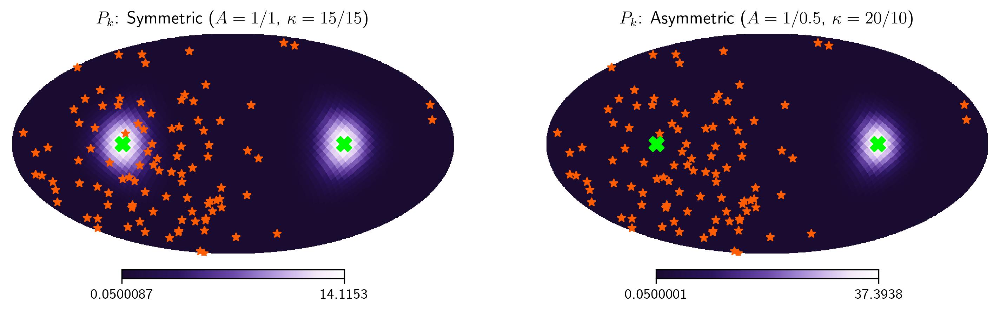

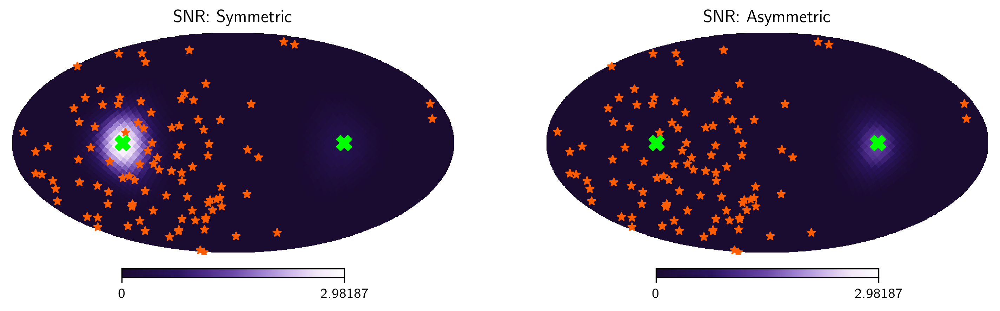

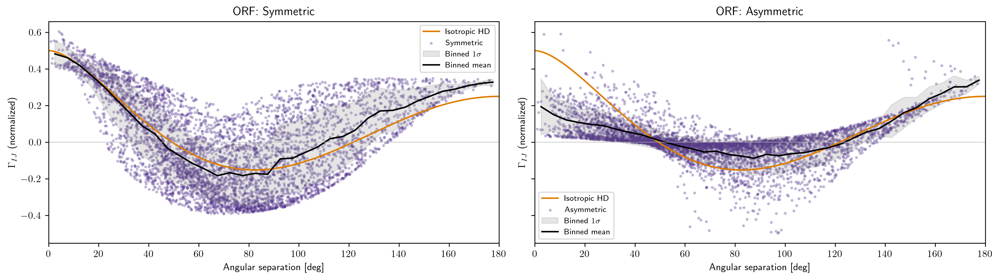

Symmetric:  SNR [0.0030, 2.9819], total=21.63
Asymmetric: SNR [0.0027, 1.4000], total=9.17


In [35]:
# Symmetric vs asymmetric two-hotspot comparison (default npix normalization)
theta_2 = [np.pi/2, np.pi/2]
phi_2   = [np.pi/2, 3*np.pi/2]

Pk_sym,  *_ = ASM.injection(NSIDE=ASM.NSIDE, theta=theta_2, phi=phi_2,
    steepness=[15.0, 15.0], amplitudes=[1.0, 1.0], f_iso=0.05)
Pk_asym, *_ = ASM.injection(NSIDE=ASM.NSIDE, theta=theta_2, phi=phi_2,
    steepness=[20.0, 10.0], amplitudes=[1.0, 0.5], f_iso=0.05)

Gamma_sym  = ASM.basis_strategy.pixel_orf(Pk_sym)
Gamma_asym = ASM.basis_strategy.pixel_orf(Pk_asym)

SNR_sym  = ASM.SNR_fk(Pk_sym,  Sh_gwb, diag=True)
SNR_asym = ASM.SNR_fk(Pk_asym, Sh_gwb, diag=True)
snr_sym_fint  = np.sqrt(np.trapezoid(SNR_sym**2, ASM.freqs, axis=0))
snr_asym_fint = np.sqrt(np.trapezoid(SNR_asym**2, ASM.freqs, axis=0))
vmax_2 = max(snr_sym_fint.max(), snr_asym_fint.max())

# Row 1: Injection maps
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, Pk, label in [(axes[0], Pk_sym, r'Symmetric ($A=1/1$, $\kappa=15/15$)'),
                       (axes[1], Pk_asym, r'Asymmetric ($A=1/0.5$, $\kappa=20/10$)')]:
    plt.sca(ax)
    hp.mollview(Pk, title=f'$P_k$: {label}', cmap='purple_cmap_r', 
                rot=(180, 0, 0), hold=True, bgcolor='white')
    for th, ph in zip(theta_2, phi_2):
        hp.projscatter([np.degrees(ph)], [90 - np.degrees(th)],
            lonlat=True, marker='X', color='lime', s=100, zorder=5)
    hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)

plt.tight_layout()
plt.show()

# Row 2: SNR maps (shared colorbar)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, snr_map, label in [(axes[0], snr_sym_fint, 'Symmetric'),
                            (axes[1], snr_asym_fint, 'Asymmetric')]:
    plt.sca(ax)
    hp.mollview(snr_map, title=f'SNR: {label}', cmap='purple_cmap_r', 
                rot=(180, 0, 0), hold=True, min=0, max=vmax_2, bgcolor='white')
    for th, ph in zip(theta_2, phi_2):
        hp.projscatter([np.degrees(ph)], [90 - np.degrees(th)],
            lonlat=True, marker='X', color='lime', s=100, zorder=5)
    hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)

plt.tight_layout()
plt.show()

# Row 3: ORF / HD curves side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
# HD analytic curve
x_hd = np.linspace(0, 180, 400)
cos_hd = np.cos(np.radians(x_hd))
hd = 1.5 * ((1 - cos_hd)/2 * np.log((1 - cos_hd)/2 + 1e-30) - (1 - cos_hd)/12) + 0.5

# Normalise the injection ORF so its envelope matches the iso curve
scale = 0.5 / max(np.max(np.abs(Gamma_iso)), 1e-30)
g_inj = Gamma_sym * scale
bc, bm, lo, hi = haniso.binned_stats(ang_sep_pairs, g_inj, bins=np.arange(0, 181, 5))

axes[0].plot(x_hd, hd, '-', color='#E07C00', lw=1.5, label='Isotropic HD')
axes[0].scatter(ang_sep_pairs, g_inj, s=4, alpha=0.25, color='#4C2C89', label='Symmetric')
axes[0].fill_between(bc, lo, hi, color='0.5', alpha=0.2, label=r'Binned $1\sigma$')
axes[0].plot(bc, bm, '-', color='k', lw=1.5, label='Binned mean')
axes[0].axhline(0, color='0.7', lw=0.5)
axes[0].set_xlabel('Angular separation [deg]')
axes[0].set_ylabel(r'$\Gamma_{IJ}$ (normalized)')
axes[0].set_title('ORF: Symmetric')
axes[0].set_xlim(0, 180)
axes[0].legend(fontsize=8, loc='best')

# HD analytic curve
x_hd = np.linspace(0, 180, 400)
cos_hd = np.cos(np.radians(x_hd))
hd = 1.5 * ((1 - cos_hd)/2 * np.log((1 - cos_hd)/2 + 1e-30) - (1 - cos_hd)/12) + 0.5

# Normalise the injection ORF so its envelope matches the iso curve
scale = 0.5 / max(np.max(np.abs(Gamma_iso)), 1e-30)
g_inj = Gamma_asym * scale
bc, bm, lo, hi = haniso.binned_stats(ang_sep_pairs, g_inj, bins=np.arange(0, 181, 5))

axes[1].plot(x_hd, hd, '-', color='#E07C00', lw=1.5, label='Isotropic HD')
axes[1].scatter(ang_sep_pairs, g_inj, s=4, alpha=0.25, color='#4C2C89', label='Asymmetric')
axes[1].fill_between(bc, lo, hi, color='0.5', alpha=0.2, label=r'Binned $1\sigma$')
axes[1].plot(bc, bm, '-', color='k', lw=1.5, label='Binned mean')
axes[1].axhline(0, color='0.7', lw=0.5)
axes[1].set_xlabel('Angular separation [deg]')
axes[1].set_ylabel(r'$\Gamma_{IJ}$ (normalized)')
axes[1].set_title('ORF: Asymmetric')
axes[1].set_xlim(0, 180)
axes[1].legend(fontsize=8, loc='best')
plt.tight_layout()
plt.show()

print(f'Symmetric:  SNR [{snr_sym_fint.min():.4f}, {snr_sym_fint.max():.4f}], '
      f'total={np.sqrt(np.sum(snr_sym_fint**2)):.2f}')
print(f'Asymmetric: SNR [{snr_asym_fint.min():.4f}, {snr_asym_fint.max():.4f}], '
      f'total={np.sqrt(np.sum(snr_asym_fint**2)):.2f}')

# Free large intermediates from this cell
del SNR_sym, SNR_asym

### Many Hotspots

With 1000 randomly placed hotspots, the sky approaches a realistic diffuse anisotropic background (e.g. from a numerous unresolved SMBHB population). With 1000 randomly placed hotspots, the sky approaches a realistic diffuse anisotropic background from a large SMBHB population.

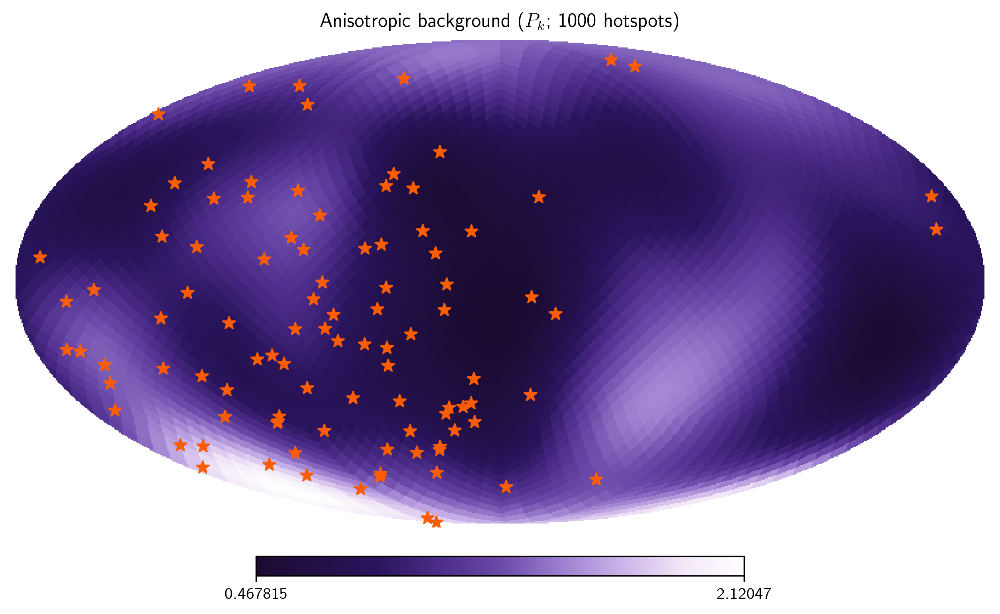

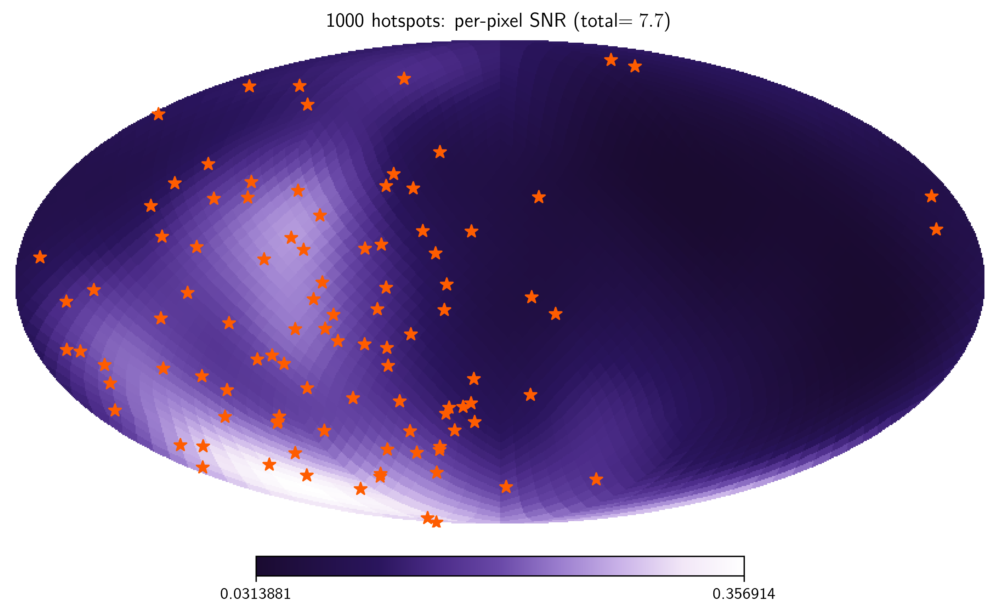

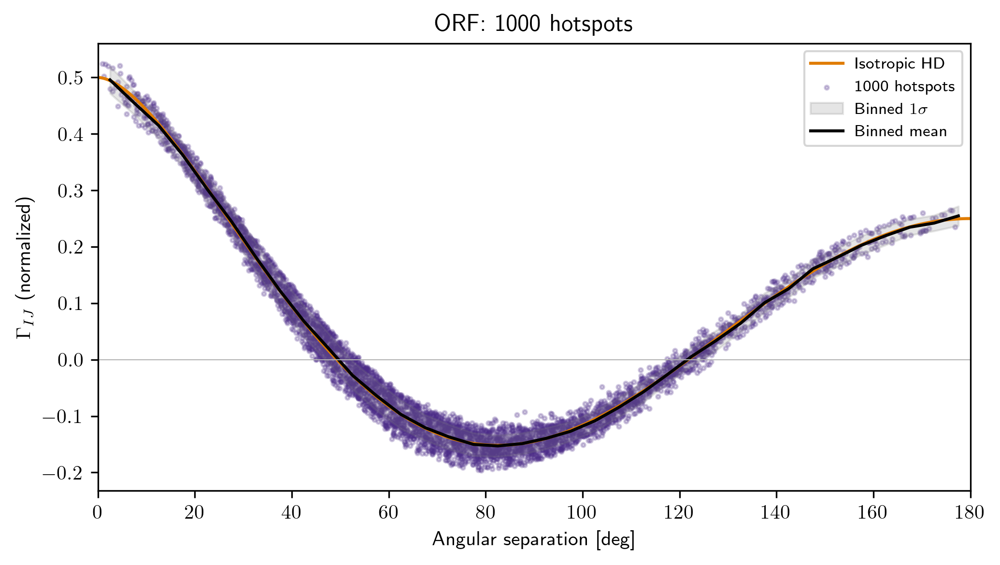

In [36]:
rng = np.random.default_rng(2026)
NPIX = ASM.NPIX
M = 1000  # number of hotspots

# Random centers (uniform on the sphere)
cos_th = rng.uniform(-1, 1, size=M)
theta_many = np.arccos(cos_th)
phi_many   = rng.uniform(0, 2*np.pi, size=M)
weights        = rng.dirichlet(alpha=np.ones(M))
steepness_many = rng.uniform(3.0, 12.0, size=M)

Pk_many, *_ = ASM.injection(
    NSIDE=ASM.NSIDE, theta=theta_many, phi=phi_many,
    amplitudes=weights, steepness=steepness_many, f_iso=0.1,
)

hp.mollview(Pk_many, title=rf'Anisotropic background ($P_k$; {M} hotspots)',
         cmap='purple_cmap_r', rot=(180, 0, 0))
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=60)
plt.show()

# Per-pixel SNR
SNR_many = ASM.SNR_fk(Pk_many, Sh_gwb, diag=True)
snr_many_fint = np.sqrt(np.trapezoid(SNR_many**2, ASM.freqs, axis=0))
total_snr_many = np.sqrt(np.sum(snr_many_fint**2))

hp.mollview(snr_many_fint,
    title=rf'{M} hotspots: per-pixel SNR (total$={total_snr_many:.1f}$)',
    cmap='purple_cmap_r', rot=(180, 0, 0))
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=60)
plt.show()

Gamma_many = ASM.basis_strategy.pixel_orf(Pk_many)
fig, ax = plt.subplots(figsize=(7, 4))
# HD analytic curve
x_hd = np.linspace(0, 180, 400)
cos_hd = np.cos(np.radians(x_hd))
hd = 1.5 * ((1 - cos_hd)/2 * np.log((1 - cos_hd)/2 + 1e-30) - (1 - cos_hd)/12) + 0.5

# Normalise the injection ORF so its envelope matches the iso curve
scale = 0.5 / max(np.max(np.abs(Gamma_iso)), 1e-30)
g_inj = Gamma_many * scale
bc, bm, lo, hi = haniso.binned_stats(ang_sep_pairs, g_inj, bins=np.arange(0, 181, 5))

ax.plot(x_hd, hd, '-', color='#E07C00', lw=1.5, label='Isotropic HD')
ax.scatter(ang_sep_pairs, g_inj, s=4, alpha=0.25, color='#4C2C89', label=f'{M} hotspots')
ax.fill_between(bc, lo, hi, color='0.5', alpha=0.2, label=r'Binned $1\sigma$')
ax.plot(bc, bm, '-', color='k', lw=1.5, label='Binned mean')
ax.axhline(0, color='0.7', lw=0.5)
ax.set_xlabel('Angular separation [deg]')
ax.set_ylabel(r'$\Gamma_{IJ}$ (normalized)')
ax.set_title(f'ORF: {M} hotspots')
ax.set_xlim(0, 180)
ax.legend(fontsize=8, loc='best')
plt.tight_layout()
plt.show()

# Free large intermediates from this cell
del SNR_many

### Frequency-dependent injection

Each hotspot can carry a frequency-dependent amplitude $w_i(f) \propto (f/f_0)^{\alpha_i}$, modeling source populations with varying spectral characteristics (sources brighter at low vs. high frequency).

In reality different frequency bins see different sky distributions because
each SMBHB emits at a specific GW frequency. The `freqs` and `evolve`
parameters model this: hotspot amplitudes can scale as power laws in
frequency, concentrations can broaden or sharpen, and centers can drift.

Below we use a per-hotspot amplitude power-law $w_i(f) \propto (f/f_0)^{\alpha_i}$.
Negative $\alpha$ means a source is brighter at low frequency; positive
$\alpha$ means it is brighter at high frequency. The resulting sky maps
and per-pixel SNRs change across the band, consistent in spirit with the
$C_\ell/C_0 \propto f^{11/3}$ scaling of
[Sato-Polito \& Kamionkowski 2024](https://arxiv.org/abs/2305.05690).


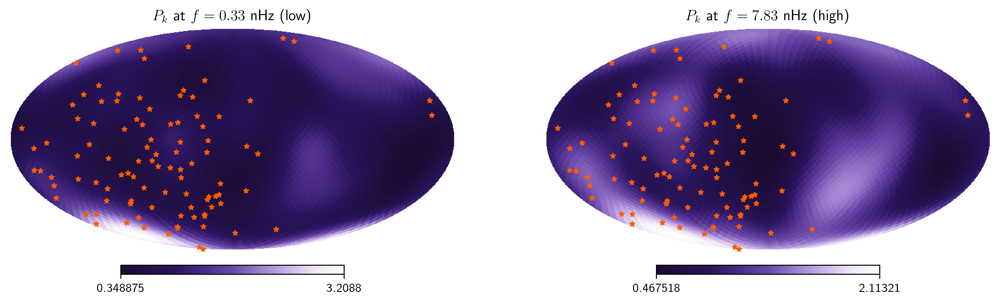

In [37]:
# Frequency-dependent injection — per-hotspot amplitude power-law
# w_i(f) ~ (f/f0)^alpha_i  (alpha<0 brighter at low f, alpha>0 brighter at high f)
alpha_evolve = rng.uniform(-2.0, 0.5, size=M)

P_fk, *_, meta = ASM.injection(
    NSIDE=ASM.NSIDE, theta=theta_many, phi=phi_many,
    amplitudes=weights, steepness=steepness_many, f_iso=0.1,
    freqs=ASM.freqs, evolve=dict(alpha=alpha_evolve),
)  # P_fk has shape (Nfreq, NPIX)

# Compare the same injection at two reference frequencies
fidx_lo = 5
fidx_hi = len(ASM.freqs) // 2

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plt.sca(axes[0])
hp.mollview(P_fk[fidx_lo],
            title=f'$P_k$ at $f={ASM.freqs[fidx_lo]*1e9:.2f}$ nHz (low)',
            cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white')
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=15)

plt.sca(axes[1])
hp.mollview(P_fk[fidx_hi],
            title=f'$P_k$ at $f={ASM.freqs[fidx_hi]*1e9:.2f}$ nHz (high)',
            cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white')
hp.projscatter(ASM.phis * 180/np.pi, 90 - ASM.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=15)

plt.tight_layout()
plt.show()

# Free large intermediates from this cell
del P_fk

### Total Detection SNR

The `SNR_total()` method integrates the per-pixel SNR over frequency and sky direction.
Two modes:

- **Radiometer** (`diag=True`): treats each pixel independently — sum of per-pixel $\mathrm{SNR}^2$
- **Full-Fisher** (`diag=False`): uses the full Fisher matrix $\mathbf{P}^T \mathbf{M}(f)\,\mathbf{P}$, exploiting correlations between pixels for higher SNR

The two totals are not ordered in general: they agree when all the power is in one pixel, the full-Fisher total is far larger for an isotropic sky, and the radiometer total can be larger when the power sits in pixels whose responses are anti-correlated.


Total detection SNR (radiometer / full-Fisher):
  Isotropic:        7.44  /  169.24
  Single hotspot:  33.60  /  320.42

Full-Fisher/radiometer SNR^2 ratio:
  Isotropic:  516.830x
  Hotspot:    90.968x


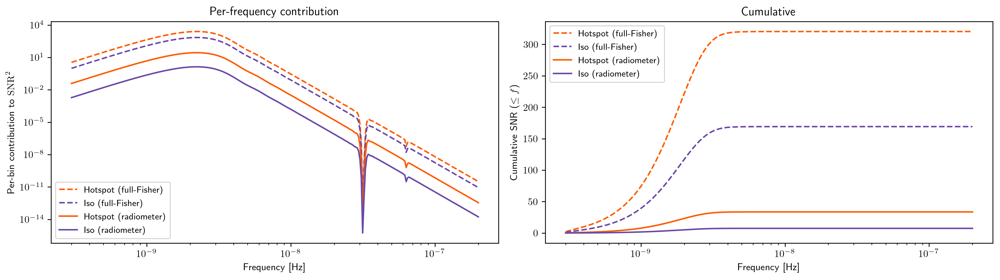

In [38]:
# Total detection SNR (radiometer + full-Fisher) for isotropic vs single-hotspot

# Compare isotropic vs single-hotspot
Pk_iso = np.ones(ASM.NPIX)
Pk_hot, _, _, _, _ = ASM.injection(ASM.NSIDE, num_of_hotspots=1, steepness=10,
                                    f_iso=0.1, rng=np.random.default_rng(2026),
                                    normalize='npix')

snr_iso_rad, snr2_iso_rad_f = ASM.SNR_total(Pk_iso, Sh_gwb, diag=True)
snr_hot_rad, snr2_hot_rad_f = ASM.SNR_total(Pk_hot, Sh_gwb, diag=True)
snr_iso_full, snr2_iso_full_f = ASM.SNR_total(Pk_iso, Sh_gwb, diag=False)
snr_hot_full, snr2_hot_full_f = ASM.SNR_total(Pk_hot, Sh_gwb, diag=False)

print('Total detection SNR (radiometer / full-Fisher):')
print(f'  Isotropic:      {snr_iso_rad:6.2f}  /  {snr_iso_full:6.2f}')
print(f'  Single hotspot: {snr_hot_rad:6.2f}  /  {snr_hot_full:6.2f}')
print(f'\nFull-Fisher/radiometer SNR^2 ratio:')
print(f'  Isotropic:  {(snr_iso_full/snr_iso_rad)**2:.3f}x')
print(f'  Hotspot:    {(snr_hot_full/snr_hot_rad)**2:.3f}x')

# Color = injection (purple iso / orange hotspot);  style = method (solid rad / dashed opt)
COLOR_ISO = '#6A49A8'
COLOR_HOT = '#FE5C00'

df = np.gradient(ASM.freqs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# Lines drawn top-to-bottom by amplitude: hotspot opt, iso opt, hotspot rad, iso rad
ax1.loglog(ASM.freqs, snr2_hot_full_f * df, color=COLOR_HOT, lw=1.5, ls='--',
           label='Hotspot (full-Fisher)')
ax1.loglog(ASM.freqs, snr2_iso_full_f * df, color=COLOR_ISO, lw=1.5, ls='--',
           label='Iso (full-Fisher)')
ax1.loglog(ASM.freqs, snr2_hot_rad_f * df, color=COLOR_HOT, lw=1.5, ls='-',
           label='Hotspot (radiometer)')
ax1.loglog(ASM.freqs, snr2_iso_rad_f * df, color=COLOR_ISO, lw=1.5, ls='-',
           label='Iso (radiometer)')
ax1.set_xlabel('Frequency [Hz]')
ax1.set_ylabel(r'Per-bin contribution to $\mathrm{SNR}^2$')
ax1.set_title('Per-frequency contribution')
ax1.legend(fontsize=9, loc='lower left')

ax2.semilogx(ASM.freqs, np.sqrt(np.cumsum(snr2_hot_full_f * df)),
             color=COLOR_HOT, lw=1.5, ls='--', label='Hotspot (full-Fisher)')
ax2.semilogx(ASM.freqs, np.sqrt(np.cumsum(snr2_iso_full_f * df)),
             color=COLOR_ISO, lw=1.5, ls='--', label='Iso (full-Fisher)')
ax2.semilogx(ASM.freqs, np.sqrt(np.cumsum(snr2_hot_rad_f * df)),
             color=COLOR_HOT, lw=1.5, ls='-', label='Hotspot (radiometer)')
ax2.semilogx(ASM.freqs, np.sqrt(np.cumsum(snr2_iso_rad_f * df)),
             color=COLOR_ISO, lw=1.5, ls='-', label='Iso (radiometer)')
ax2.set_xlabel('Frequency [Hz]')
ax2.set_ylabel(r'Cumulative SNR ($\leq f$)')
ax2.set_title('Cumulative')
ax2.legend(fontsize=9, loc='upper left')

plt.tight_layout()
plt.show()


# Forecasting

How does anisotropic sensitivity evolve as the PTA grows? We compare a 15-year simulated PTA with a 30-year simulated PTA (the full simulated array with more pulsars and longer baselines).

Forecasting how per-direction sensitivity, per-pixel detection statistics, and the Fisher angular response evolve as a PTA grows in baseline and pulsar count. Below we compare `ASM_15` (100 pulsars × 15 yr) with `ASM_30` (150 pulsars × 30 yr — the same 100 pulsars with longer baselines plus 50 new ones). The same code path produces the forecast for any user-supplied array configuration; the simulated arrays here are illustrative.

In [39]:
# Forecasting setup: build Anisotropy objects for both configurations
N15 = len(specs_15)
N30 = len(specs_30)

# Same NSIDE for both so the comparison is fair (driven by the smaller array)
NSIDE_fc = 2 ** int(np.floor(np.log2(((N15*(N15-1))/24)**0.5)))
NPIX_fc = hp.nside2npix(NSIDE_fc)
theta_pix_fc, phi_pix_fc = hp.pix2ang(NSIDE_fc, np.arange(NPIX_fc))

ASM_15 = haniso.Anisotropy(specs_15, theta_pix_fc, phi_pix_fc,
                           NSIDE=NSIDE_fc, basis="pixel")
ASM_30 = haniso.Anisotropy(specs_30, theta_pix_fc, phi_pix_fc,
                           NSIDE=NSIDE_fc, basis="pixel")

print(f"ASM_15: {N15} pulsars / 15 yr")
print(f"ASM_30: {N30} pulsars / 30 yr")
print(f"NSIDE = {NSIDE_fc}, NPIX = {NPIX_fc}")


ASM_15: 100 pulsars / 15 yr
ASM_30: 150 pulsars / 30 yr
NSIDE = 16, NPIX = 3072


## Angular Response

With no injected anisotropy, the $S_{\mathrm{eff}}$ maps show how the
PTA's intrinsic angular response improves from 15 to 30 years. Both panels
share the same color scale for direct comparison.


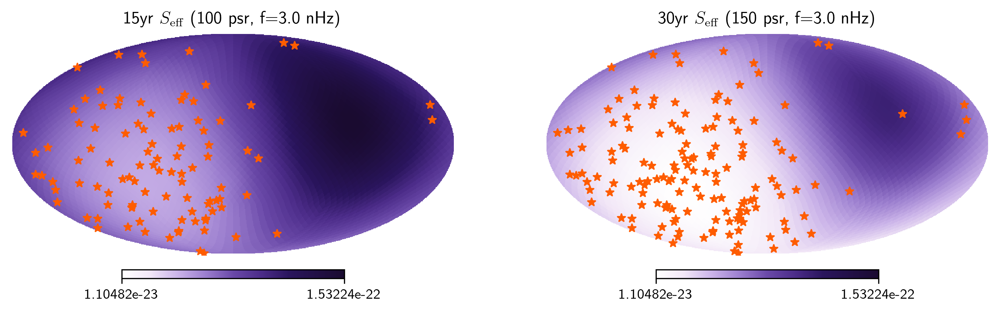

comparison frequency: 3.01 nHz (15-year peak)
15yr median S_eff @ fc: 4.31e-23
30yr median S_eff @ fc: 2.14e-23
Improvement @ same freq: 2.0x


In [40]:
# S_eff comparison: 15yr vs 30yr (isotropic)
# Both arrays are evaluated at the SAME frequency for an apples-to-apples
# comparison: the 15-year array's peak-sensitivity frequency (fidx_15).
# fidx_30 is kept only to report the 30yr array at its own optimum.
S_eff_15 = ASM_15.S_eff_fk(diag=True)
S_eff_30 = ASM_30.S_eff_fk(diag=True)

fidx_15 = np.argmin(np.median(S_eff_15, axis=1))
fidx_30 = np.argmin(np.median(S_eff_30, axis=1))
fc = fidx_15  # shared comparison frequency index

# Shared range so the two panels are directly comparable
vmin_s = min(S_eff_15[fc].min(), S_eff_30[fc].min())
vmax_s = max(S_eff_15[fc].max(), S_eff_30[fc].max())
f_nHz = ASM_15.freqs[fc] * 1e9

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plt.sca(axes[0])
hp.mollview(S_eff_15[fc], 
    title=f'15yr $S_{{\\mathrm{{eff}}}}$ ({N15} psr, f={f_nHz:.1f} nHz)',
    cmap='purple_cmap', rot=(180, 0, 0), hold=True, bgcolor='white', norm='log',
    min=vmin_s, max=vmax_s)
hp.projscatter(ASM_15.phis * 180/np.pi, 90 - ASM_15.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)

plt.sca(axes[1])
hp.mollview(S_eff_30[fc], 
    title=f'30yr $S_{{\\mathrm{{eff}}}}$ ({N30} psr, f={f_nHz:.1f} nHz)',
    cmap='purple_cmap', rot=(180, 0, 0), hold=True, bgcolor='white', norm='log',
    min=vmin_s, max=vmax_s)
hp.projscatter(ASM_30.phis * 180/np.pi, 90 - ASM_30.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)

plt.tight_layout()
plt.show()

print(f'comparison frequency: {f_nHz:.2f} nHz (15-year peak)')
print(f'15yr median S_eff @ fc: {np.median(S_eff_15[fc]):.2e}')
print(f'30yr median S_eff @ fc: {np.median(S_eff_30[fc]):.2e}')
print(f'Improvement @ same freq: {np.median(S_eff_15[fc])/np.median(S_eff_30[fc]):.1f}x')


### Per-pixel sensitivity curves

The shaded regions show the range from most sensitive (lower bound) to least sensitive (upper bound) pixel, for both 15yr and 30yr. The 30yr array is uniformly more sensitive across all frequencies and sky directions.

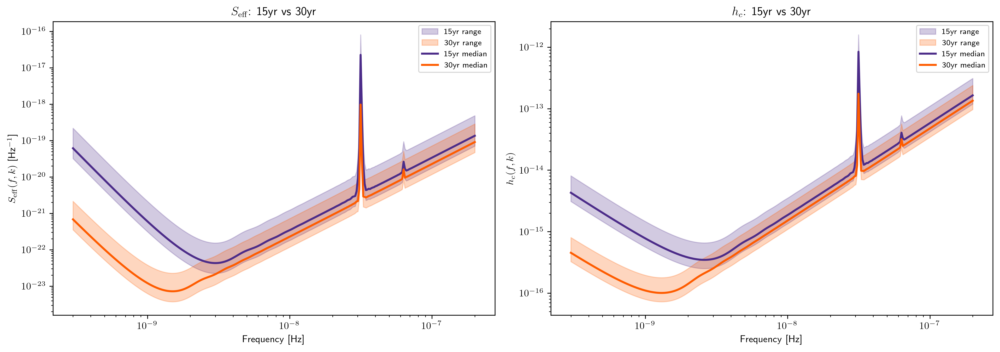

In [41]:
# Per-pixel sensitivity curves: 15yr (dark purple) vs 30yr (orange)
h_c_16 = np.sqrt(ASM_15.freqs[:, None] * S_eff_15)
h_c_40 = np.sqrt(ASM_30.freqs[:, None] * S_eff_30)

C16 = '#4C2C89'      # dark purple
C40 = pulsar_color   # orange (defined at notebook top)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# S_eff
ax1.fill_between(ASM_15.freqs, S_eff_15.min(axis=1), S_eff_15.max(axis=1),
                 color=C16, alpha=0.25, label='15yr range')
ax1.fill_between(ASM_30.freqs, S_eff_30.min(axis=1), S_eff_30.max(axis=1),
                 color=C40, alpha=0.25, label='30yr range')
ax1.loglog(ASM_15.freqs, np.median(S_eff_15, axis=1), color=C16, lw=2,
           label='15yr median')
ax1.loglog(ASM_30.freqs, np.median(S_eff_30, axis=1), color=C40, lw=2,
           label='30yr median')
ax1.set_xlabel('Frequency [Hz]')
ax1.set_ylabel(r'$S_{\mathrm{eff}}(f, k)$ [Hz$^{-1}$]')
ax1.set_title(r'$S_{\mathrm{eff}}$: 15yr vs 30yr')
ax1.legend(fontsize=8)

# h_c
ax2.fill_between(ASM_15.freqs, h_c_16.min(axis=1), h_c_16.max(axis=1),
                 color=C16, alpha=0.25, label='15yr range')
ax2.fill_between(ASM_30.freqs, h_c_40.min(axis=1), h_c_40.max(axis=1),
                 color=C40, alpha=0.25, label='30yr range')
ax2.loglog(ASM_15.freqs, np.median(h_c_16, axis=1), color=C16, lw=2,
           label='15yr median')
ax2.loglog(ASM_30.freqs, np.median(h_c_40, axis=1), color=C40, lw=2,
           label='30yr median')
ax2.set_xlabel('Frequency [Hz]')
ax2.set_ylabel(r'$h_c(f, k)$')
ax2.set_title(r'$h_c$: 15yr vs 30yr')
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()

# Free large intermediates from this cell
del h_c_16, h_c_40

## Single Hotspot Forecast

Same single-hotspot injection applied to both 15yr and 30yr arrays. The SNR maps share the same colorbar for direct comparison.

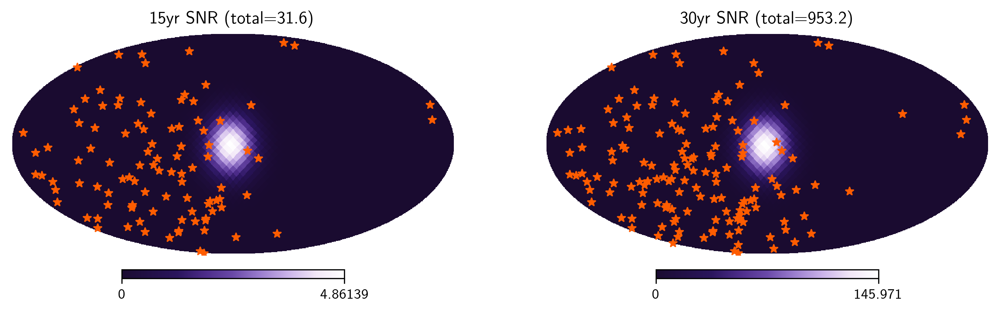

15yr total SNR: 31.6
30yr total SNR: 953.2
SNR improvement: 30.2x


In [42]:
# Single hotspot: 15yr vs 30yr
Pk_fc, *_ = ASM_15.injection(NSIDE=NSIDE_fc, theta=np.pi/2, phi=np.pi,
                              steepness=18.0, f_iso=0.05)

Sh_fc = hsen.S_h(A=A_gwb, alpha=-2/3, freqs=ASM_15.freqs)

SNR_16 = ASM_15.SNR_fk(Pk_fc, Sh_fc, diag=True)
SNR_40 = ASM_30.SNR_fk(Pk_fc, Sh_fc, diag=True)
snr_16 = np.sqrt(np.trapezoid(SNR_16**2, ASM_15.freqs, axis=0))
snr_40 = np.sqrt(np.trapezoid(SNR_40**2, ASM_30.freqs, axis=0))
vmax_15, vmax_30 = snr_16.max(), snr_40.max()

# Total integrated SNR via the standard SNR_total method (consistent with
# the isotropic-validation cross-check elsewhere in the notebook).
snr_tot_16, _ = ASM_15.SNR_total(Pk_fc, Sh_fc, diag=True)
snr_tot_40, _ = ASM_30.SNR_total(Pk_fc, Sh_fc, diag=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plt.sca(axes[0])
hp.mollview(snr_16, title=f'15yr SNR (total={snr_tot_16:.1f})', 
    cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white', min=0, max=vmax_15)
hp.projscatter(ASM_15.phis * 180/np.pi, 90 - ASM_15.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)

plt.sca(axes[1])
hp.mollview(snr_40, title=f'30yr SNR (total={snr_tot_40:.1f})', 
    cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white', min=0, max=vmax_30)
hp.projscatter(ASM_30.phis * 180/np.pi, 90 - ASM_30.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)

plt.tight_layout()
plt.show()

print(f'15yr total SNR: {snr_tot_16:.1f}')
print(f'30yr total SNR: {snr_tot_40:.1f}')
print(f'SNR improvement: {snr_tot_40/snr_tot_16:.1f}x')

# Free large intermediates from this cell
del SNR_16, SNR_40

## Many Hotspots Forecast

A diffuse anisotropic background (1000 hotspots) applied to both arrays.

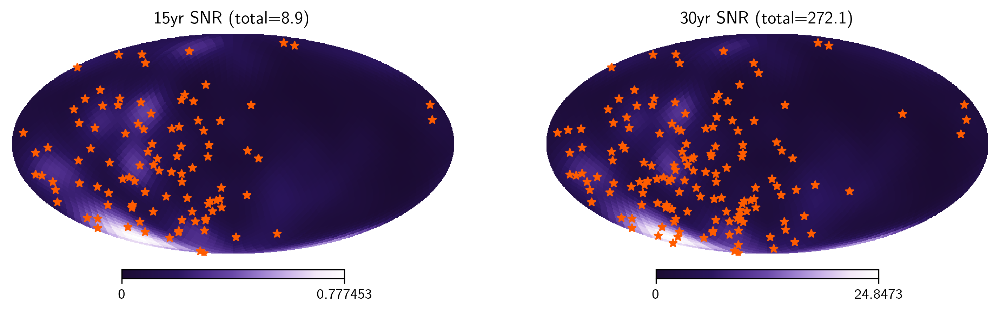

15yr total SNR: 8.9
30yr total SNR: 272.1
SNR improvement: 30.7x
Note: "total SNR" here is the integrated detection statistic returned by ASM.SNR_total() (frequency- and sky-integrated), not a simple sum over pixels.


In [43]:
# Many hotspots: 15yr vs 30yr
rng_fc = np.random.default_rng(2026)
M_fc = 1000
cos_th_fc = rng_fc.uniform(-1, 1, size=M_fc)
theta_fc = np.arccos(cos_th_fc)
phi_fc = rng_fc.uniform(0, 2*np.pi, size=M_fc)
w_fc = rng_fc.dirichlet(alpha=np.ones(M_fc))
kappa_fc = rng_fc.uniform(8.0, 25.0, size=M_fc) 

Pk_mfc, *_ = ASM_15.injection(NSIDE=NSIDE_fc, theta=theta_fc, phi=phi_fc,
                               amplitudes=w_fc, steepness=kappa_fc,
                               f_iso=0.05)

SNR_m16 = ASM_15.SNR_fk(Pk_mfc, Sh_fc, diag=True)
SNR_m40 = ASM_30.SNR_fk(Pk_mfc, Sh_fc, diag=True)
snr_m16 = np.sqrt(np.trapezoid(SNR_m16**2, ASM_15.freqs, axis=0))
snr_m40 = np.sqrt(np.trapezoid(SNR_m40**2, ASM_30.freqs, axis=0))
vmax_m15, vmax_m30 = snr_m16.max(), snr_m40.max()

# Total integrated SNR via the SNR_total method (matches the isotropic
# cross-check used elsewhere in the notebook; not just a sum over pixels).
snr_tot_m16, _ = ASM_15.SNR_total(Pk_mfc, Sh_fc, diag=True)
snr_tot_m40, _ = ASM_30.SNR_total(Pk_mfc, Sh_fc, diag=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plt.sca(axes[0])
hp.mollview(snr_m16, title=f'15yr SNR (total={snr_tot_m16:.1f})', 
    cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white', min=0, max=vmax_m15)
hp.projscatter(ASM_15.phis * 180/np.pi, 90 - ASM_15.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)

plt.sca(axes[1])
hp.mollview(snr_m40, title=f'30yr SNR (total={snr_tot_m40:.1f})', 
    cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white', min=0, max=vmax_m30)
hp.projscatter(ASM_30.phis * 180/np.pi, 90 - ASM_30.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)

plt.tight_layout()
plt.show()

print(f'15yr total SNR: {snr_tot_m16:.1f}')
print(f'30yr total SNR: {snr_tot_m40:.1f}')
print(f'SNR improvement: {snr_tot_m40/snr_tot_m16:.1f}x')
print('Note: "total SNR" here is the integrated detection statistic returned '
      'by ASM.SNR_total() (frequency- and sky-integrated), not a simple '
      'sum over pixels.')

# Free large intermediates from this cell
del SNR_m16, SNR_m40

## Full-Fisher/radiometer ratio: 15yr vs 30yr

How does the full-Fisher-to-radiometer per-pixel std ratio change as the array
grows?  Both panels share the same colorbar.  If the ratio decreases with
more pulsars, it means inter-pixel correlations weaken (more independent
information per direction); if it stays the same or grows, it means the
new pulsars also contribute correlated coverage.


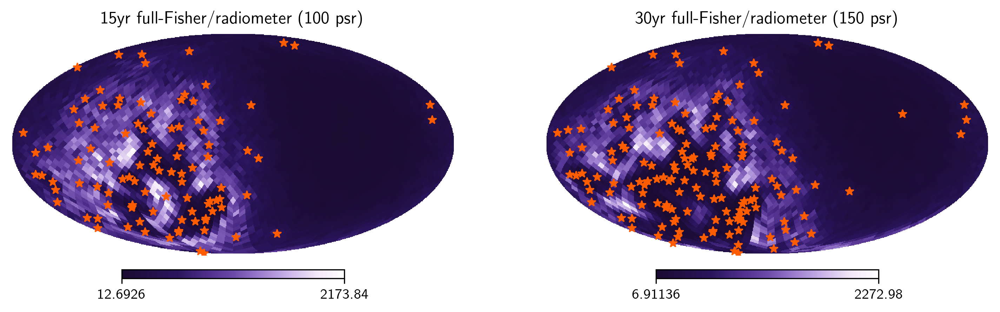

Note: the absolute magnitude of the ratio depends on the SVD truncation choice (rcond) and is regularization-dependent. The side-by-side maps are a visual comparison of correlation structure across configurations.


In [44]:
# Full-Fisher/radiometer S_eff ratio: 15yr vs 30yr  (both at the shared 15yr peak, fc)
# 15yr full Fisher
S_eff_full_15 = ASM_15.S_eff_fk(diag=False, freqs_idx=[fc])[0]
ratio_15 = S_eff_full_15 / S_eff_15[fc]

# 30yr full Fisher
S_eff_full_30 = ASM_30.S_eff_fk(diag=False, freqs_idx=[fc])[0]
ratio_30 = S_eff_full_30 / S_eff_30[fc]

# Per-panel ranges
vmin_r15, vmax_r15 = ratio_15.min(), ratio_15.max()
vmin_r30, vmax_r30 = ratio_30.min(), ratio_30.max()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plt.sca(axes[0])
hp.mollview(ratio_15, 
    title=f'15yr full-Fisher/radiometer ({N15} psr)',
    cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white',
    min=vmin_r15, max=vmax_r15)
hp.projscatter(ASM_15.phis * 180/np.pi, 90 - ASM_15.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)

plt.sca(axes[1])
hp.mollview(ratio_30, 
    title=f'30yr full-Fisher/radiometer ({N30} psr)',
    cmap='purple_cmap_r', rot=(180, 0, 0), hold=True, bgcolor='white',
    min=vmin_r30, max=vmax_r30)
hp.projscatter(ASM_30.phis * 180/np.pi, 90 - ASM_30.thetas * 180/np.pi,
               lonlat=True, marker='*', color=pulsar_color, s=30)

plt.tight_layout()
plt.show()

print('Note: the absolute magnitude of the ratio depends on the SVD '
      'truncation choice (rcond) and is regularization-dependent. The '
      'side-by-side maps are a visual comparison of correlation structure '
      'across configurations.')
